# Import与预处理

In [4]:
import json
from collections import Counter
import os
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pandas as pd
import numpy as np
import matplotlib.colors as mcolors
from ollama import AsyncClient
from openai import AsyncClient, AsyncOpenAI
import random
from matplotlib.sankey import Sankey
import matplotlib.font_manager as fm

In [5]:
font_path = 'font/MSYH.TTC'
fm.fontManager.addfont(font_path)
font_name = fm.FontProperties(fname=font_path).get_name()
plt.rcParams['font.family'] = 'serif'  # 将默认字体族设置为衬线字体
plt.rcParams['font.serif'] = [font_name] # 设置衬线字体为我们刚注册的字体
plt.rcParams['axes.unicode_minus'] = False

In [6]:
model_name = "Qwen2.5-14B-Instruct"
rootdir = f"results/exp1/{model_name}"

topic_list = [file.split('.')[0] for file in os.listdir(rootdir)]

topic_list = [x for x in topic_list]
# 重新排序 topic_list，先按第一个元素，再按第二个元素
topic_list = sorted(
    topic_list,
    key=lambda x: (x.split('_')[0], x.split('_')[1])
)
topic_list

['academia_fact_conflict',
 'athlete_fact_conflict',
 'government_fact_conflict',
 'honor_fact_conflict',
 'identity_fact_conflict',
 'location_fact_conflict',
 'organization_fact_conflict',
 'production_fact_conflict']

In [7]:
topic_list = ["学术", "体育", "人物", "历史", "宗教", "地理", "音乐", "媒体"]

In [8]:
# colormap
USER_NUM = 100
DAY_NUM = 10
TOPIC_NUM = len(topic_list)
colormap = sns.color_palette("coolwarm", as_cmap=True)
colormap = [colormap(i/4) for i in range(5)]

# 图1，图2

## 图1
混合三种LLM的fact相关数据，统计初次遇到虚假信息时的态度分布并绘图

共发现24个json文件


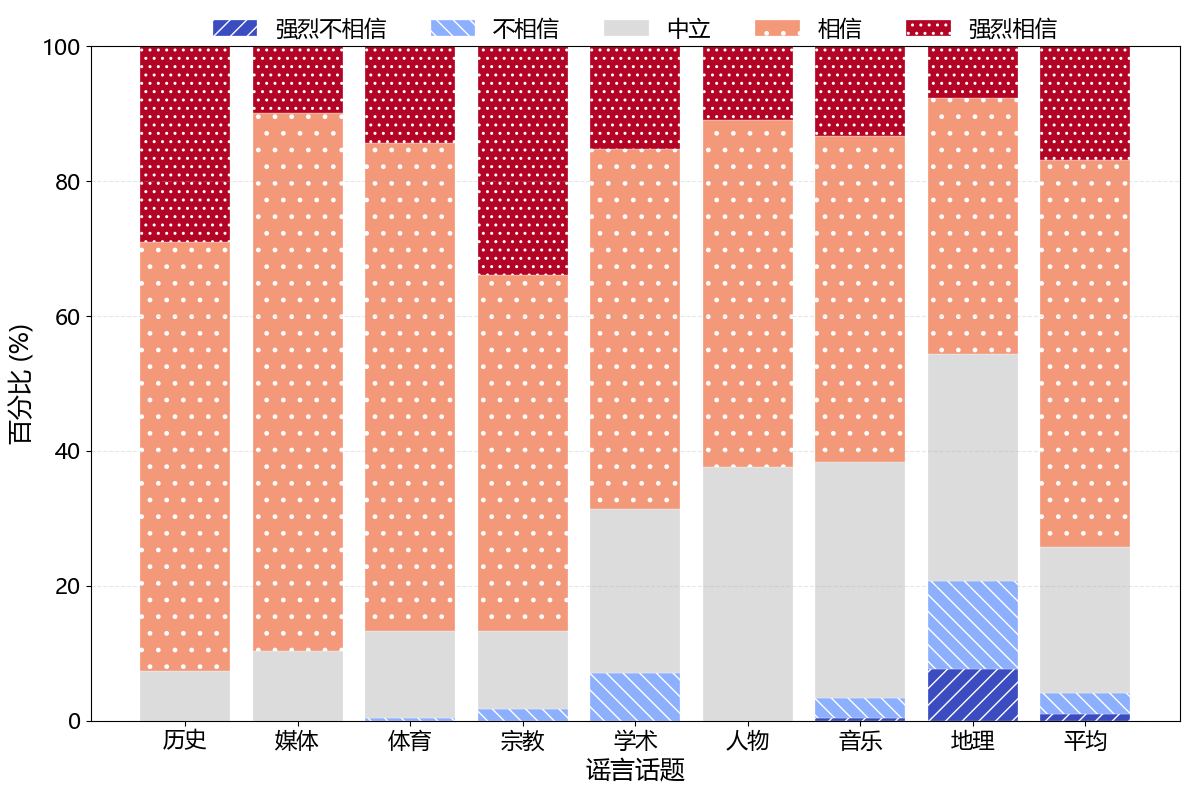

In [22]:
# 混合三种LLM的fact相关数据，统计初次遇到虚假信息时的态度分布并绘图
import glob
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import matplotlib.font_manager as fm

# 1. 收集所有fact相关json文件路径
# llm_dirs = [
#     'results/exp1/GLM-4-9B-Chat',
#     'results/exp1/Llama-3.1-8B-Instruct',
#     'results/exp1/Qwen2.5-14B-Instruct'
#  ]

llm_dirs = [
    'modified_results/exp1/GLM-4-9B-Chat',
    'modified_results/exp1/Llama-3.1-8B-Instruct',
    'modified_results/exp1/Qwen2.5-14B-Instruct'
 ]

all_json_files = []
for d in llm_dirs:
    all_json_files.extend(glob.glob(os.path.join(d, '*.json')))

print(f'共发现{len(all_json_files)}个json文件')

# 2. 统计所有话题名（去掉后缀和路径，合并去重，字典序排序）
topic_names = sorted(list(set([os.path.basename(f).replace('.json','') for f in all_json_files])))
chinese_topic_names = [topic_list[i] for i in range(len(topic_names))]

# 3. 统计每个话题下所有LLM的初次态度
attitude_labels = ['强烈不相信', '不相信', '中立', '相信', '强烈相信']
attitude_counts = np.zeros((len(topic_names)+1, 5), dtype=int)  # +1 for Overall

USER_NUM = 100  # 每个话题每个LLM 100个智能体，若有不同请修改
for i, topic in enumerate(topic_names):
    topic_files = [f for f in all_json_files if os.path.basename(f).startswith(topic)]
    for file in topic_files:
        with open(file, 'r', encoding='utf-8') as f:
            data = json.load(f)
        # 只统计第0天的态度
        for item in data:
            if ('persuasion_tweet' in item) or ('tweet' in item) or ('content' in item):
                continue
            if 'new_attitude_digit' in item:
                att = item['new_attitude_digit']
            else:
                op = item.get('new_opinion_digit','')
                if op == 4: att = 4
                elif op == 3: att = 3
                elif op == 2: att = 2
                elif op == 1: att = 1
                elif op == 0: att = 0
                else: continue
            if 'day' in item and item['day'] == 0:
                attitude_counts[i, att] += 1
            elif 'round' in item and item['round'] == 0:
                attitude_counts[i, att] += 1

# 4. 统计Overall
attitude_counts[-1] = attitude_counts[:-1].sum(axis=0)

# 5. 计算百分比
attitude_percent = attitude_counts / attitude_counts.sum(axis=1, keepdims=True) * 100
positive_percent = attitude_percent[:-1, 3:].sum(axis=1)
sorted_indices = np.argsort(positive_percent)[::-1]
sorted_topic_names = [chinese_topic_names[i] for i in sorted_indices]
sorted_attitude_percent = np.vstack([attitude_percent[i] for i in sorted_indices] + [attitude_percent[-1]])

colormap = sns.color_palette("coolwarm", as_cmap=True)
colormap = [colormap(i/4) for i in range(5)]
hatch_patterns = ['//', '\\\\', '', '.', '..']
# font_name = fm.FontProperties(fname=font_path).get_name()
# plt.rcParams['font.family'] = 'serif'
# plt.rcParams['font.serif'] = [font_name]
# plt.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(12, 8))
bottom = np.zeros(len(sorted_attitude_percent))
for i, attitude in enumerate(attitude_labels):
    ax.bar(
        range(len(sorted_attitude_percent)), 
        sorted_attitude_percent[:, i], 
        bottom=bottom,
        color=colormap[i],
        edgecolor='white',
        linewidth=0.2,
        hatch=hatch_patterns[i],
        label=attitude,
        width=0.8
    )
    bottom += sorted_attitude_percent[:, i]

TITLE_FONT_SIZE = 18
LABEL_FONT_SIZE = 16
TICK_FONT_SIZE = 16
LEGEND_FONT_SIZE = 16
ax.set_xlabel('谣言话题', fontsize=TITLE_FONT_SIZE)
ax.set_ylabel('百分比 (%)', fontsize=TITLE_FONT_SIZE)
ax.set_ylim(0, 100)
ax.set_xticks(range(len(sorted_attitude_percent)))
ax.set_xticklabels(sorted_topic_names + ['平均'], rotation=0, fontsize=TICK_FONT_SIZE)
ax.tick_params(axis='y', labelsize=TICK_FONT_SIZE)
# 修改图例布局，在上方中心平铺为一行
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.07), ncol=5, frameon=False, fontsize=LEGEND_FONT_SIZE)
ax.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()

# 确保 picture 目录存在
os.makedirs('modified_picture', exist_ok=True)
# plt.savefig('picture/图1.svg', format='svg')
# plt.savefig('picture/图1.pdf', format='pdf')
plt.savefig('modified_picture/1215/图1_1215.png', format='png', dpi=600)
plt.show()

共发现24个json文件


/tmp/ipykernel_416096/4042937622.py:111: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f'{int(y)}%' for y in ax.get_yticks()])


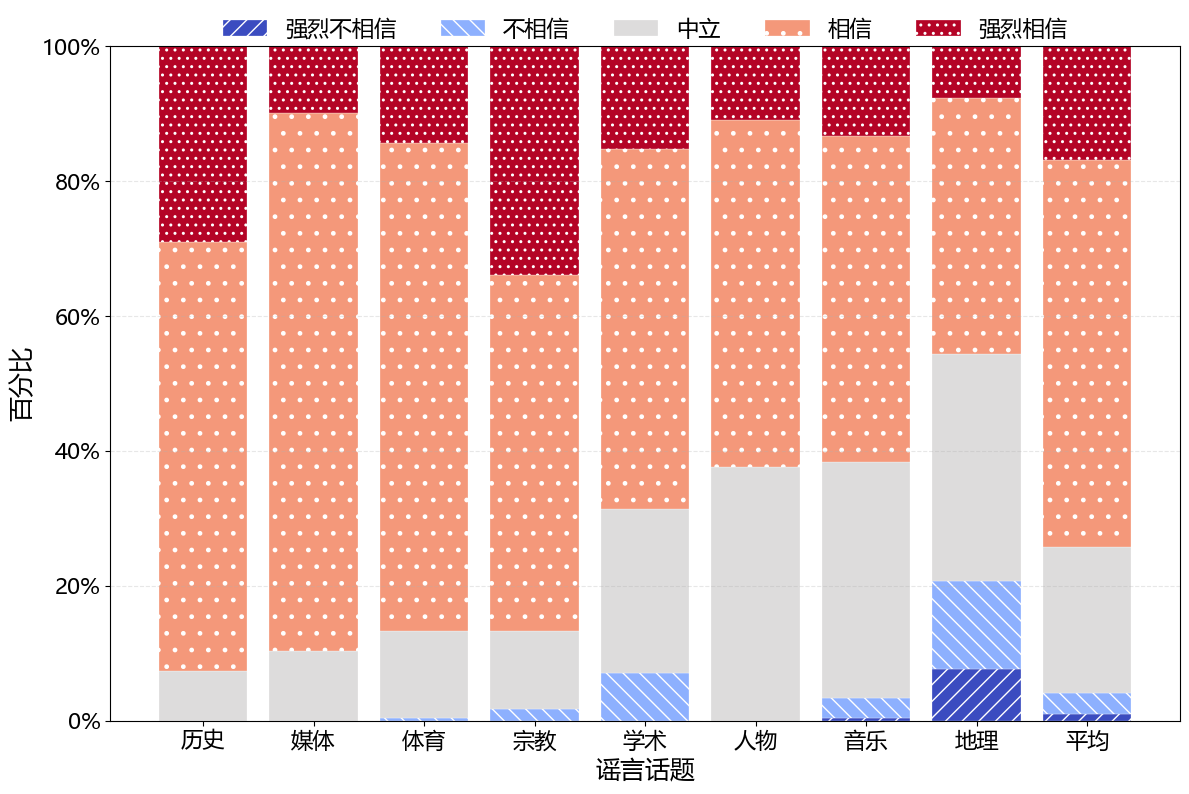

In [9]:
# 混合三种LLM的fact相关数据，统计初次遇到虚假信息时的态度分布并绘图
import glob
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import matplotlib.font_manager as fm

# 1. 收集所有fact相关json文件路径
# llm_dirs = [
#     'results/exp1/GLM-4-9B-Chat',
#     'results/exp1/Llama-3.1-8B-Instruct',
#     'results/exp1/Qwen2.5-14B-Instruct'
#  ]

llm_dirs = [
    'modified_results/exp1/GLM-4-9B-Chat',
    'modified_results/exp1/Llama-3.1-8B-Instruct',
    'modified_results/exp1/Qwen2.5-14B-Instruct'
 ]

all_json_files = []
for d in llm_dirs:
    all_json_files.extend(glob.glob(os.path.join(d, '*.json')))

print(f'共发现{len(all_json_files)}个json文件')

# 2. 统计所有话题名（去掉后缀和路径，合并去重，字典序排序）
topic_names = sorted(list(set([os.path.basename(f).replace('.json','') for f in all_json_files])))
chinese_topic_names = [topic_list[i] for i in range(len(topic_names))]

# 3. 统计每个话题下所有LLM的初次态度
attitude_labels = ['强烈不相信', '不相信', '中立', '相信', '强烈相信']
attitude_counts = np.zeros((len(topic_names)+1, 5), dtype=int)  # +1 for Overall

USER_NUM = 100  # 每个话题每个LLM 100个智能体，若有不同请修改
for i, topic in enumerate(topic_names):
    topic_files = [f for f in all_json_files if os.path.basename(f).startswith(topic)]
    for file in topic_files:
        with open(file, 'r', encoding='utf-8') as f:
            data = json.load(f)
        # 只统计第0天的态度
        for item in data:
            if ('persuasion_tweet' in item) or ('tweet' in item) or ('content' in item):
                continue
            if 'new_attitude_digit' in item:
                att = item['new_attitude_digit']
            else:
                op = item.get('new_opinion_digit','')
                if op == 4: att = 4
                elif op == 3: att = 3
                elif op == 2: att = 2
                elif op == 1: att = 1
                elif op == 0: att = 0
                else: continue
            if 'day' in item and item['day'] == 0:
                attitude_counts[i, att] += 1
            elif 'round' in item and item['round'] == 0:
                attitude_counts[i, att] += 1

# 4. 统计Overall
attitude_counts[-1] = attitude_counts[:-1].sum(axis=0)

# 5. 计算百分比
attitude_percent = attitude_counts / attitude_counts.sum(axis=1, keepdims=True) * 100
positive_percent = attitude_percent[:-1, 3:].sum(axis=1)
sorted_indices = np.argsort(positive_percent)[::-1]
sorted_topic_names = [chinese_topic_names[i] for i in sorted_indices]
sorted_attitude_percent = np.vstack([attitude_percent[i] for i in sorted_indices] + [attitude_percent[-1]])

colormap = sns.color_palette("coolwarm", as_cmap=True)
colormap = [colormap(i/4) for i in range(5)]
hatch_patterns = ['//', '\\\\', '', '.', '..']
# font_name = fm.FontProperties(fname=font_path).get_name()
# plt.rcParams['font.family'] = 'serif'
# plt.rcParams['font.serif'] = [font_name]
# plt.rcParams['axes.unicode_minus'] = False


# 修改图形中的ylabel和yticks标签
fig, ax = plt.subplots(figsize=(12, 8))
bottom = np.zeros(len(sorted_attitude_percent))
for i, attitude in enumerate(attitude_labels):
    ax.bar(
        range(len(sorted_attitude_percent)), 
        sorted_attitude_percent[:, i], 
        bottom=bottom,
        color=colormap[i],
        edgecolor='white',
        linewidth=0.2,
        hatch=hatch_patterns[i],
        label=attitude,
        width=0.8
    )
    bottom += sorted_attitude_percent[:, i]

TITLE_FONT_SIZE = 18
LABEL_FONT_SIZE = 16
TICK_FONT_SIZE = 16
LEGEND_FONT_SIZE = 16
ax.set_xlabel('谣言话题', fontsize=TITLE_FONT_SIZE)
ax.set_ylabel('百分比', fontsize=TITLE_FONT_SIZE)  # 去掉了百分号
ax.set_ylim(0, 100)
ax.set_xticks(range(len(sorted_attitude_percent)))
ax.set_xticklabels(sorted_topic_names + ['平均'], rotation=0, fontsize=TICK_FONT_SIZE)
ax.tick_params(axis='y', labelsize=TICK_FONT_SIZE)

# 修改y轴的ticklabel，加上百分号
ax.set_yticklabels([f'{int(y)}%' for y in ax.get_yticks()])

# 修改图例布局，在上方中心平铺为一行
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.07), ncol=5, frameon=False, fontsize=LEGEND_FONT_SIZE)
ax.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()

# 确保 picture 目录存在
os.makedirs('modified_picture/1227', exist_ok=True)
plt.savefig('modified_picture/1227/图1_1227.png', format='png', dpi=600)
plt.show()

#### 提取matlab需要的文档

In [10]:
import glob
import json
import os
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.io import savemat

def load_topic_display_names(topic_names):
    """
    你原代码里用的是 topic_list[i] 作为中文名。
    这里提供一个“可选映射”机制：
    - 如果当前目录有 topic_display_map.json，按映射替换显示名
      格式示例：{"topic_file_stem_1":"中文名1", "topic_file_stem_2":"中文名2"}
    - 否则默认显示 topic_names 本身
    """
    map_path = "topic_display_map.json"
    if os.path.exists(map_path):
        with open(map_path, "r", encoding="utf-8") as f:
            mp = json.load(f)
        return [mp.get(t, t) for t in topic_names]
    return topic_names


def main():
    # 1) LLM 文件夹
    llm_dirs = [
        "modified_results/exp1/GLM-4-9B-Chat",
        "modified_results/exp1/Llama-3.1-8B-Instruct",
        "modified_results/exp1/Qwen2.5-14B-Instruct",
    ]

    # 2) 收集所有 json
    all_json_files = []
    for d in llm_dirs:
        all_json_files.extend(glob.glob(os.path.join(d, "*.json")))
    print(f"共发现 {len(all_json_files)} 个 json 文件")

    if len(all_json_files) == 0:
        raise RuntimeError("没有找到任何 json 文件，请检查 llm_dirs 路径是否正确。")

    # 3) 话题名（stem）
    topic_names = sorted(list({os.path.basename(f).replace(".json", "") for f in all_json_files}))
    display_topic_names = load_topic_display_names(topic_names)

    # 4) 统计初次(day/round=0)态度分布
    attitude_labels = ["强烈不相信", "不相信", "中立", "相信", "强烈相信"]
    attitude_counts = np.zeros((len(topic_names) + 1, 5), dtype=int)  # +1 Overall

    for i, topic in enumerate(topic_names):
        topic_files = [f for f in all_json_files if os.path.basename(f).startswith(topic)]
        for file in topic_files:
            with open(file, "r", encoding="utf-8") as f:
                data = json.load(f)

            for item in data:
                # 跳过推文/内容项
                if ("persuasion_tweet" in item) or ("tweet" in item) or ("content" in item):
                    continue

                # 取态度 digit（优先 new_attitude_digit）
                if "new_attitude_digit" in item:
                    att = item["new_attitude_digit"]
                else:
                    op = item.get("new_opinion_digit", "")
                    if op in [0, 1, 2, 3, 4]:
                        att = op
                    else:
                        continue

                # 只统计第0天/第0轮
                if ("day" in item and item["day"] == 0) or ("round" in item and item["round"] == 0):
                    if 0 <= att <= 4:
                        attitude_counts[i, att] += 1

    # Overall
    attitude_counts[-1] = attitude_counts[:-1].sum(axis=0)

    # 5) 百分比 + 按“正向(相信+强烈相信)”排序
    row_sums = attitude_counts.sum(axis=1, keepdims=True)
    attitude_percent = np.divide(attitude_counts, row_sums, out=np.zeros_like(attitude_counts, dtype=float), where=row_sums != 0) * 100

    positive_percent = attitude_percent[:-1, 3:].sum(axis=1)  # 每话题“相信+强烈相信”
    sorted_indices = np.argsort(positive_percent)[::-1]

    sorted_topic_names = [display_topic_names[i] for i in sorted_indices]
    sorted_attitude_percent = np.vstack([attitude_percent[i] for i in sorted_indices] + [attitude_percent[-1]])
    x_labels = sorted_topic_names + ["平均"]  # 和你原图一致

    # 6) 导出颜色（确保 Matlab 和 Python 一致）
    cmap = sns.color_palette("coolwarm", as_cmap=True)
    colors = np.array([cmap(i / 4)[:3] for i in range(5)], dtype=float)  # 5x3 RGB

    hatch_patterns = np.array(["//", "\\\\", "", ".", ".."], dtype=object)

    # 7) 导出 .mat（Matlab 直接 load）
    out_mat = "plot_data.mat"
    savemat(
        out_mat,
        {
            "x_labels": np.array(x_labels, dtype=object),
            "topic_names_sorted": np.array(sorted_topic_names, dtype=object),
            "attitude_labels": np.array(attitude_labels, dtype=object),
            "attitude_percent": sorted_attitude_percent,  # (num_topics+1) x 5
            "colors_rgb": colors,  # 5 x 3
            "hatch_patterns": hatch_patterns,
        },
        do_compression=True,
    )
    print(f"已保存: {out_mat}")

    # 8) 额外导出 CSV（便于肉眼检查）
    out_csv = "plot_data.csv"
    df = pd.DataFrame(sorted_attitude_percent, columns=attitude_labels)
    df.insert(0, "topic", x_labels)
    df.to_csv(out_csv, index=False, encoding="utf-8-sig")
    print(f"已保存: {out_csv}")

In [11]:
main()

共发现 24 个 json 文件
已保存: plot_data.mat
已保存: plot_data.csv


## 图2
混合所有LLM和话题，统计每一轮（天）所有智能体的态度分布并绘图

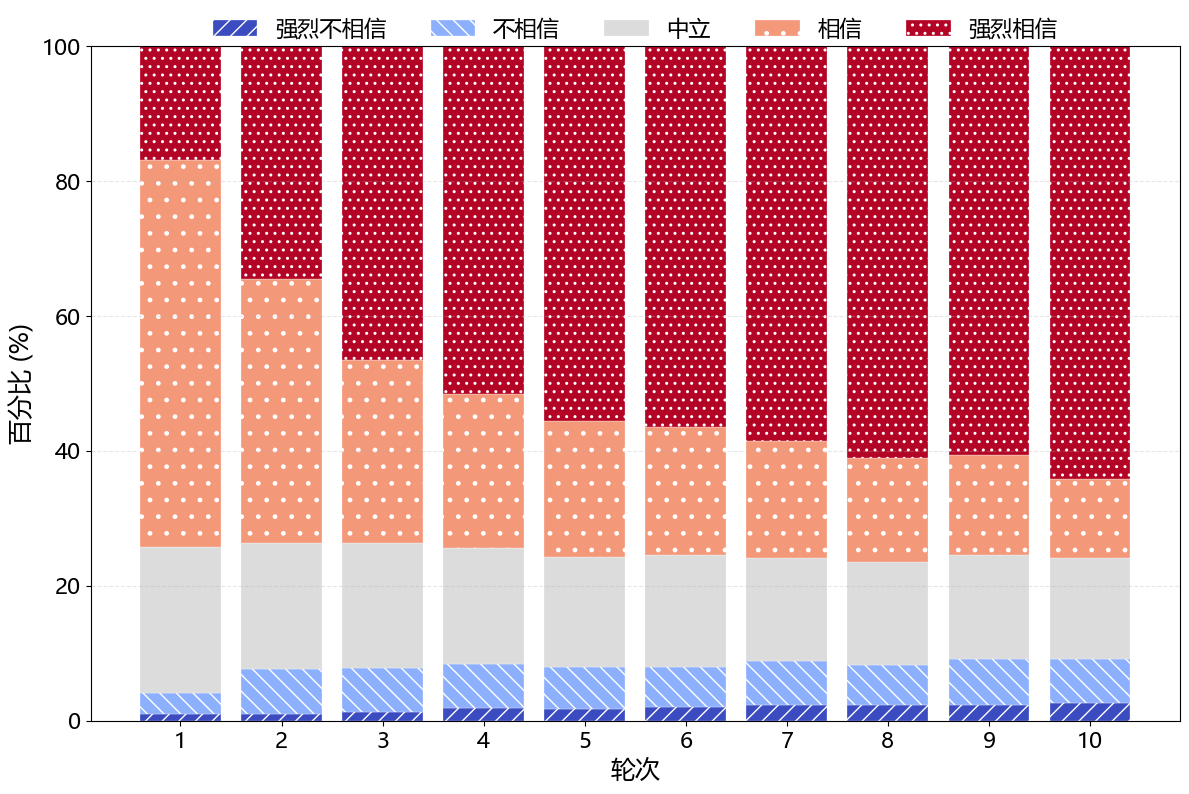

In [17]:
# 混合所有LLM和话题，统计每一轮（天）所有智能体的态度分布并绘图
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm

# llm_dirs = [
#     'results/exp1/GLM-4-9B-Chat',
#     'results/exp1/Llama-3.1-8B-Instruct',
#     'results/exp1/Qwen2.5-14B-Instruct'
#  ]

llm_dirs = [
    'modified_results/exp1/GLM-4-9B-Chat',
    'modified_results/exp1/Llama-3.1-8B-Instruct',
    'modified_results/exp1/Qwen2.5-14B-Instruct'
 ]

all_json_files = []
for d in llm_dirs:
    all_json_files.extend(glob.glob(os.path.join(d, '*.json')))
    
# 1. 统计每一轮所有智能体的态度分布
DAY_NUM = 10
attitude_labels = ['强烈不相信', '不相信', '中立', '相信', '强烈相信']
attitude_counts_by_day = np.zeros((DAY_NUM, 5), dtype=int)

for file in all_json_files:
    with open(file, 'r', encoding='utf-8') as f:
        data = json.load(f)
    for item in data:
        if ('persuasion_tweet' in item) or ('tweet' in item) or ('content' in item):
            continue
        if 'new_attitude_digit' in item:
            att = item['new_attitude_digit']
        else:
            op = item.get('new_opinion_digit','')
            if op == 4: att = 4
            elif op == 3: att = 3
            elif op == 2: att = 2
            elif op == 1: att = 1
            elif op == 0: att = 0
            else: continue
        if 'day' in item:
            day = item['day']
        elif 'round' in item:
            day = item['round']
        else:
            continue
        if 0 <= day < DAY_NUM:
            attitude_counts_by_day[day, att] += 1

# 2. 计算百分比
attitude_percent_by_day = attitude_counts_by_day / attitude_counts_by_day.sum(axis=1, keepdims=True) * 100

# 3. 绘图（风格与前一图一致）
colormap = sns.color_palette("coolwarm", as_cmap=True)
colormap = [colormap(i/4) for i in range(5)]
hatch_patterns = ['//', '\\\\', '', '.', '..']
font_name = fm.FontProperties(fname=font_path).get_name()
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = [font_name]
plt.rcParams['axes.unicode_minus'] = False

TITLE_FONT_SIZE = 18
LABEL_FONT_SIZE = 16
TICK_FONT_SIZE = 16
LEGEND_FONT_SIZE = 16

fig, ax = plt.subplots(figsize=(12, 8))
bottom = np.zeros(DAY_NUM)
for i, attitude in enumerate(attitude_labels):
    ax.bar(
        np.arange(1, DAY_NUM+1), 
        attitude_percent_by_day[:, i], 
        bottom=bottom,
        color=colormap[i],
        edgecolor='white',
        linewidth=0.2,
        hatch=hatch_patterns[i],
        label=attitude,
        width=0.8
    )
    bottom += attitude_percent_by_day[:, i]

ax.set_xlabel('轮次', fontsize=TITLE_FONT_SIZE)
ax.set_ylabel('百分比 (%)', fontsize=TITLE_FONT_SIZE)
ax.set_ylim(0, 100)
ax.set_xticks(np.arange(1, DAY_NUM+1))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.07), ncol=5, frameon=False, fontsize=LEGEND_FONT_SIZE)
ax.grid(axis='y', alpha=0.3, linestyle='--')

ax.tick_params(axis='x', labelsize=TICK_FONT_SIZE)
ax.tick_params(axis='y', labelsize=TICK_FONT_SIZE)


plt.tight_layout()
# plt.savefig('picture/图2.svg', format='svg')
plt.savefig('modified_picture/1215/图2.png', format='png', dpi=600)
# plt.savefig('picture/图2.pdf', format='pdf')
plt.show()

/tmp/ipykernel_65211/1217158242.py:96: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f'{int(y)}%' for y in ax.get_yticks()])


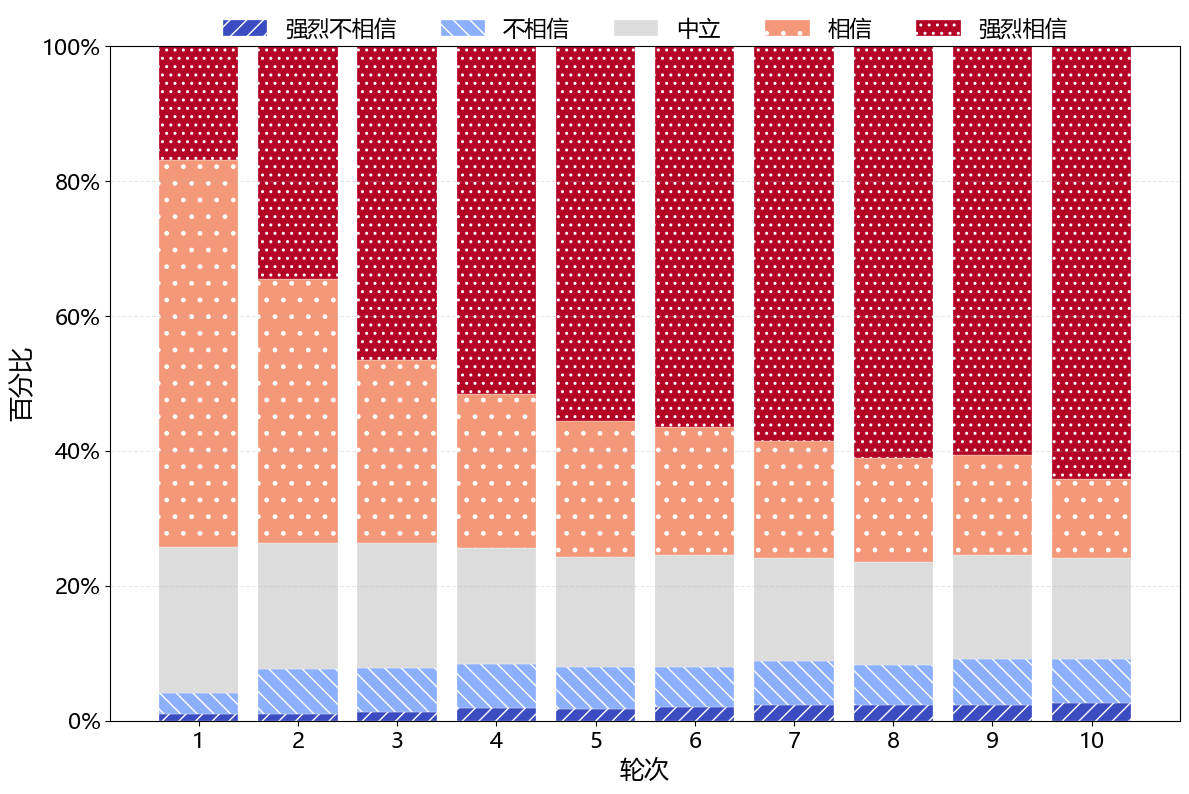

In [24]:
# 混合所有LLM和话题，统计每一轮（天）所有智能体的态度分布并绘图
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm

# llm_dirs = [
#     'results/exp1/GLM-4-9B-Chat',
#     'results/exp1/Llama-3.1-8B-Instruct',
#     'results/exp1/Qwen2.5-14B-Instruct'
#  ]

llm_dirs = [
    'modified_results/exp1/GLM-4-9B-Chat',
    'modified_results/exp1/Llama-3.1-8B-Instruct',
    'modified_results/exp1/Qwen2.5-14B-Instruct'
 ]

all_json_files = []
for d in llm_dirs:
    all_json_files.extend(glob.glob(os.path.join(d, '*.json')))
    
# 1. 统计每一轮所有智能体的态度分布
DAY_NUM = 10
attitude_labels = ['强烈不相信', '不相信', '中立', '相信', '强烈相信']
attitude_counts_by_day = np.zeros((DAY_NUM, 5), dtype=int)

for file in all_json_files:
    with open(file, 'r', encoding='utf-8') as f:
        data = json.load(f)
    for item in data:
        if ('persuasion_tweet' in item) or ('tweet' in item) or ('content' in item):
            continue
        if 'new_attitude_digit' in item:
            att = item['new_attitude_digit']
        else:
            op = item.get('new_opinion_digit','')
            if op == 4: att = 4
            elif op == 3: att = 3
            elif op == 2: att = 2
            elif op == 1: att = 1
            elif op == 0: att = 0
            else: continue
        if 'day' in item:
            day = item['day']
        elif 'round' in item:
            day = item['round']
        else:
            continue
        if 0 <= day < DAY_NUM:
            attitude_counts_by_day[day, att] += 1

# 2. 计算百分比
attitude_percent_by_day = attitude_counts_by_day / attitude_counts_by_day.sum(axis=1, keepdims=True) * 100

# 3. 绘图（风格与前一图一致）
colormap = sns.color_palette("coolwarm", as_cmap=True)
colormap = [colormap(i/4) for i in range(5)]
hatch_patterns = ['//', '\\\\', '', '.', '..']
font_name = fm.FontProperties(fname=font_path).get_name()
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = [font_name]
plt.rcParams['axes.unicode_minus'] = False

TITLE_FONT_SIZE = 18
LABEL_FONT_SIZE = 16
TICK_FONT_SIZE = 16
LEGEND_FONT_SIZE = 16

fig, ax = plt.subplots(figsize=(12, 8))
bottom = np.zeros(DAY_NUM)
for i, attitude in enumerate(attitude_labels):
    ax.bar(
        np.arange(1, DAY_NUM+1), 
        attitude_percent_by_day[:, i], 
        bottom=bottom,
        color=colormap[i],
        edgecolor='white',
        linewidth=0.2,
        hatch=hatch_patterns[i],
        label=attitude,
        width=0.8
    )
    bottom += attitude_percent_by_day[:, i]

ax.set_xlabel('轮次', fontsize=TITLE_FONT_SIZE)
ax.set_ylabel('百分比', fontsize=TITLE_FONT_SIZE)
ax.set_ylim(0, 100)
ax.set_xticks(np.arange(1, DAY_NUM+1))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.07), ncol=5, frameon=False, fontsize=LEGEND_FONT_SIZE)
ax.grid(axis='y', alpha=0.3, linestyle='--')

ax.tick_params(axis='x', labelsize=TICK_FONT_SIZE)
ax.tick_params(axis='y', labelsize=TICK_FONT_SIZE)
# 修改y轴的ticklabel，加上百分号
ax.set_yticklabels([f'{int(y)}%' for y in ax.get_yticks()])

plt.tight_layout()
# plt.savefig('picture/图2.svg', format='svg')
plt.savefig('modified_picture/1227/图2_1227.png', format='png', dpi=600)
# plt.savefig('picture/图2.pdf', format='pdf')
plt.show()

### 提取matlab需要的文档

In [12]:
import glob
import json
import os
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.io import savemat


def main():
    # 1) LLM 文件夹
    llm_dirs = [
        "modified_results/exp1/GLM-4-9B-Chat",
        "modified_results/exp1/Llama-3.1-8B-Instruct",
        "modified_results/exp1/Qwen2.5-14B-Instruct",
    ]

    # 2) 收集所有 json
    all_json_files = []
    for d in llm_dirs:
        all_json_files.extend(glob.glob(os.path.join(d, "*.json")))
    print(f"共发现 {len(all_json_files)} 个 json 文件")

    if len(all_json_files) == 0:
        raise RuntimeError("没有找到任何 json 文件，请检查 llm_dirs 路径是否正确。")

    # 3) 统计配置
    DAY_NUM = 10
    attitude_labels = ["强烈不相信", "不相信", "中立", "相信", "强烈相信"]
    hatch_patterns = np.array(["//", "\\\\", "", ".", ".."], dtype=object)

    # 4) 统计每一轮(day/round)态度分布（混合所有 LLM + 所有话题）
    attitude_counts_by_day = np.zeros((DAY_NUM, 5), dtype=int)

    def extract_attitude(item):
        """优先 new_attitude_digit，否则退化 new_opinion_digit；返回 0..4 或 None"""
        if "new_attitude_digit" in item:
            try:
                att = int(item["new_attitude_digit"])
            except Exception:
                return None
            return att if 0 <= att <= 4 else None

        op = item.get("new_opinion_digit", None)
        if op is None:
            return None
        try:
            op = int(op)
        except Exception:
            return None
        return op if 0 <= op <= 4 else None

    def extract_day(item):
        """day 优先，否则 round；返回 int 或 None"""
        if "day" in item:
            v = item["day"]
        elif "round" in item:
            v = item["round"]
        else:
            return None
        try:
            v = int(v)
        except Exception:
            return None
        return v

    for file in all_json_files:
        with open(file, "r", encoding="utf-8") as f:
            data = json.load(f)

        for item in data:
            # 跳过推文/内容项
            if ("persuasion_tweet" in item) or ("tweet" in item) or ("content" in item):
                continue

            att = extract_attitude(item)
            if att is None:
                continue

            day = extract_day(item)
            if day is None:
                continue

            if 0 <= day < DAY_NUM:
                attitude_counts_by_day[day, att] += 1

    # 5) 百分比（避免除0）
    row_sums = attitude_counts_by_day.sum(axis=1, keepdims=True)
    attitude_percent_by_day = np.divide(
        attitude_counts_by_day,
        row_sums,
        out=np.zeros_like(attitude_counts_by_day, dtype=float),
        where=row_sums != 0,
    ) * 100.0

    # 6) x_labels：1..DAY_NUM（与图一致）
    day_labels = np.arange(1, DAY_NUM + 1, dtype=int)
    x_labels = [str(i) for i in day_labels]

    # 7) 导出颜色（确保 Matlab 和 Python 一致）
    cmap = sns.color_palette("coolwarm", as_cmap=True)
    colors = np.array([cmap(i / 4)[:3] for i in range(5)], dtype=float)  # 5x3 RGB in [0,1]

    # 8) 导出 .mat（Matlab 直接 load）
    out_mat = "plot_data_by_day.mat"
    savemat(
        out_mat,
        {
            "DAY_NUM": np.array([DAY_NUM], dtype=int),
            "x_labels": np.array(x_labels, dtype=object),
            "day_labels": day_labels,
            "attitude_labels": np.array(attitude_labels, dtype=object),
            "attitude_counts_by_day": attitude_counts_by_day,
            "attitude_percent_by_day": attitude_percent_by_day,  # DAY_NUM x 5
            "colors_rgb": colors,  # 5 x 3 (0..1)
            "hatch_patterns": hatch_patterns,
        },
        do_compression=True,
    )
    print(f"已保存: {out_mat}")

    # 9) 额外导出 CSV（便于肉眼检查）
    out_csv = "plot_data_by_day.csv"
    df = pd.DataFrame(attitude_percent_by_day, columns=attitude_labels)
    df.insert(0, "round", day_labels)  # 1..DAY_NUM
    df.to_csv(out_csv, index=False, encoding="utf-8-sig")
    print(f"已保存: {out_csv}")

    # 10) 简单自检输出
    print("[CHECK] 每轮总计数:", row_sums.ravel())
    print("[CHECK] 每轮百分比求和(应≈100):", attitude_percent_by_day.sum(axis=1))

In [13]:
main()

共发现 24 个 json 文件
已保存: plot_data_by_day.mat
已保存: plot_data_by_day.csv
[CHECK] 每轮总计数: [2400 2396 2398 2395 2397 2393 2390 2391 2388 2389]
[CHECK] 每轮百分比求和(应≈100): [100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


## 多轮次图

In [15]:
def extract_distribution_evaluation(all_logs, filenames, num_rounds, user_num, topic_num = 8):
    attitude_per_round = [np.zeros((5)) for _ in range(num_rounds)]
    for filename, logs in zip(filenames, all_logs):
        for log in logs:
            if 'agent_id' in log:
                assert 'round' in log, log
                assert 'new_opinion_digit' in log, log
                assert isinstance(log['round'], int), log
                assert isinstance(log['new_opinion_digit'], int), log
                attitude_per_round[log['round']][log['new_opinion_digit']] += 1
    attitude_distribution = [attitude / (user_num * topic_num) * 100 for attitude in attitude_per_round]
    return attitude_distribution
    

In [16]:
MODEL_NAMES = ["Qwen2.5-14B-Instruct", "GLM-4-9B-Chat", "Llama-3.1-8B-Instruct"]

In [17]:
# 提取原先的实验设置_多模型
USER_NUM = 100
ROUND_NUM = 20
att_100users = np.zeros((len(MODEL_NAMES), 5, ROUND_NUM))  # shape (3, 5, 20)
for model_name in MODEL_NAMES:
    root = f"./modified_results/exp1/{model_name}_{USER_NUM}_{ROUND_NUM}"
    filenames = os.listdir(root)
    files = []
    for filename in filenames:
        with open(os.path.join(root, filename), 'r', encoding='utf-8') as f:
            data = json.load(f)
            files.append(data)
    print(f"Processing model: {model_name}, number of files: {len(files)}")
    attribution = extract_distribution_evaluation(files, filenames, num_rounds=ROUND_NUM, user_num=USER_NUM, topic_num=8)
    attribution = np.vstack(attribution)  # shape (10, 5)
    attribution = attribution.T # transpose to shape (5, 10)
    att_100users[MODEL_NAMES.index(model_name)] = attribution
# average across models -> shape (5, 20)
att_100users = att_100users.mean(axis=0)
assert att_100users.shape == (5, ROUND_NUM)

Processing model: Qwen2.5-14B-Instruct, number of files: 8
Processing model: GLM-4-9B-Chat, number of files: 8
Processing model: Llama-3.1-8B-Instruct, number of files: 8


In [18]:
# 提取原先的实验设置_多模型
USER_NUM = 150
ROUND_NUM = 20
att_150users = np.zeros((len(MODEL_NAMES), 5, ROUND_NUM))  # shape (3, 5, 20)
for model_name in MODEL_NAMES:
    root = f"./modified_results/exp1/{model_name}_{USER_NUM}_{ROUND_NUM}"
    filenames = os.listdir(root)
    files = []
    for filename in filenames:
        with open(os.path.join(root, filename), 'r', encoding='utf-8') as f:
            data = json.load(f)
            files.append(data)
    print(f"Processing model: {model_name}, number of files: {len(files)}")
    attribution = extract_distribution_evaluation(files, filenames, num_rounds=ROUND_NUM, user_num=USER_NUM, topic_num=8)
    attribution = np.vstack(attribution)  # shape (10, 5)
    attribution = attribution.T # transpose to shape (5, 10)
    att_150users[MODEL_NAMES.index(model_name)] = attribution
# average across models -> shape (5, 20)
att_150users = att_150users.mean(axis=0)
assert att_150users.shape == (5, ROUND_NUM)

Processing model: Qwen2.5-14B-Instruct, number of files: 8
Processing model: GLM-4-9B-Chat, number of files: 8
Processing model: Llama-3.1-8B-Instruct, number of files: 8


In [19]:
# 提取原先的实验设置_多模型
USER_NUM = 200
ROUND_NUM = 20
att_200users = np.zeros((len(MODEL_NAMES), 5, ROUND_NUM))  # shape (3, 5, 20)
for model_name in MODEL_NAMES:
    root = f"./modified_results/exp1/{model_name}_{USER_NUM}_{ROUND_NUM}"
    filenames = os.listdir(root)
    files = []
    for filename in filenames:
        with open(os.path.join(root, filename), 'r', encoding='utf-8') as f:
            data = json.load(f)
            files.append(data)
    print(f"Processing model: {model_name}, number of files: {len(files)}")
    attribution = extract_distribution_evaluation(files, filenames, num_rounds=ROUND_NUM, user_num=USER_NUM, topic_num=8)
    attribution = np.vstack(attribution)  # shape (10, 5)
    attribution = attribution.T # transpose to shape (5, 10)
    att_200users[MODEL_NAMES.index(model_name)] = attribution
# average across models -> shape (5, 20)
att_200users = att_200users.mean(axis=0)
assert att_200users.shape == (5, ROUND_NUM)

Processing model: Qwen2.5-14B-Instruct, number of files: 8
Processing model: GLM-4-9B-Chat, number of files: 8
Processing model: Llama-3.1-8B-Instruct, number of files: 8


/tmp/ipykernel_416096/550259734.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(np.arange(0, 110, 20), fontsize=LABEL_FONT_SIZE)
/tmp/ipykernel_416096/550259734.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(np.arange(0, 110, 20), fontsize=LABEL_FONT_SIZE)
/tmp/ipykernel_416096/550259734.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(np.arange(0, 110, 20), fontsize=LABEL_FONT_SIZE)


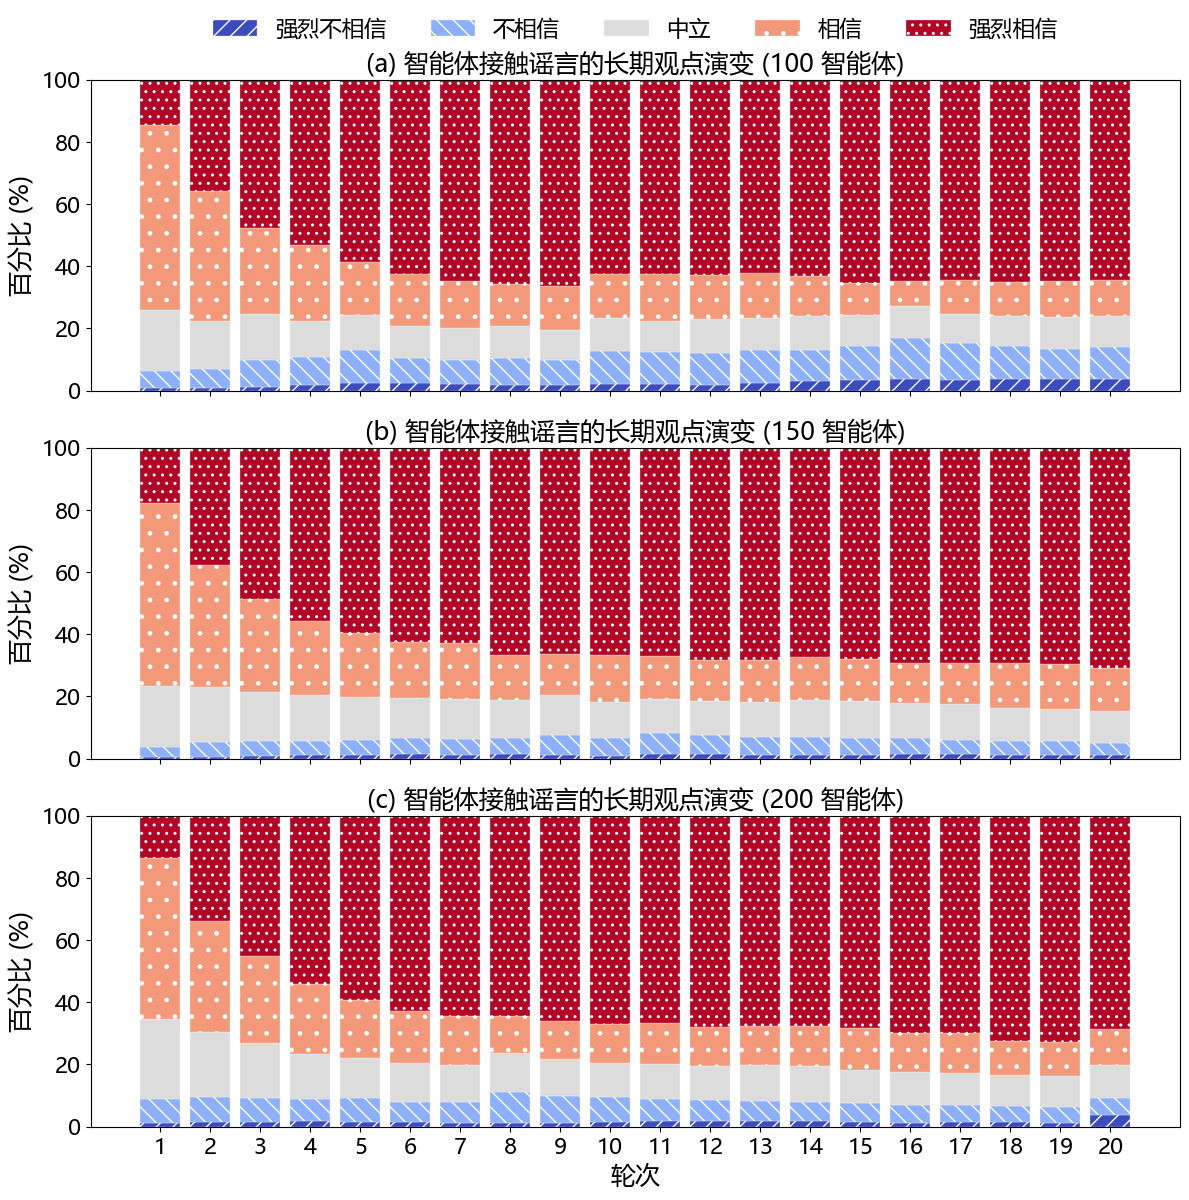

/tmp/ipykernel_416096/550259734.py:79: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_single.set_yticklabels(np.arange(0, 110, 20), fontsize=LABEL_FONT_SIZE)
/tmp/ipykernel_416096/550259734.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_single.set_yticklabels([f'{int(y)}%' for y in ax_single.get_yticks()])
/tmp/ipykernel_416096/550259734.py:79: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_single.set_yticklabels(np.arange(0, 110, 20), fontsize=LABEL_FONT_SIZE)
/tmp/ipykernel_416096/550259734.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_single.set_yticklabels([f'{int(y)}%' for y in ax_single.get_yticks()])
/tmp/ipykernel_416096/5502

In [20]:
# 绘制 att_100users、att_150users 和 att_200users 的堆叠柱状图（每轮 5 类态度的百分比）
datasets = [att_100users, att_150users, att_200users]
titles = [
    "智能体接触谣言的长期观点演变 (100 智能体)",
    "智能体接触谣言的长期观点演变 (150 智能体)",
    "智能体接触谣言的长期观点演变 (200 智能体)",
]

# 设定三个子图
fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

hatch_patterns = ['//', '\\\\', '', '.', '..']
labels = ['强烈不相信', '不相信', '中立', '相信', '强烈相信']
colormap = sns.color_palette("coolwarm", as_cmap=True)
colormap = [colormap(i/4) for i in range(5)]

TITLE_FONT_SIZE = 18
LABEL_FONT_SIZE = 16
TICK_FONT_SIZE = 16
LEGEND_FONT_SIZE = 16

# 创建子图
for idx, (ax, data, title) in enumerate(zip(axes, datasets, titles)):
    rounds = np.arange(data.shape[1])
    bottom = np.zeros(data.shape[1])
    for i, (row, color, label) in enumerate(zip(data, colormap, labels)):
        ax.bar(rounds, 
               row, 
               bottom=bottom, 
               color=color, 
               label=label, 
               hatch=hatch_patterns[i], 
               edgecolor='white',
               linewidth=0.2,
               width=0.8)
        bottom += row
    ax.set_ylabel("百分比 (%)", fontsize=TITLE_FONT_SIZE)
    ax.set_title(f"({chr(97 + idx)}) {title}", fontdict={'fontsize': TITLE_FONT_SIZE})  # 添加 a, b, c 标签
    ax.set_ylim(0, 100)
    ax.set_yticklabels(np.arange(0, 110, 20), fontsize=LABEL_FONT_SIZE)
    ax.set_xticks(np.arange(0, ROUND_NUM, 1))
    ax.tick_params(axis='x', labelsize=TICK_FONT_SIZE)
    ax.tick_params(axis='y', labelsize=TICK_FONT_SIZE)
    # ax.grid(True)

axes[-1].set_xlabel("轮次", fontsize=TITLE_FONT_SIZE)
axes[-1].set_xticklabels(np.arange(1, ROUND_NUM + 1, 1), fontsize=TICK_FONT_SIZE)
# 只在第一个子图显示图例，避免重复
axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, 1.26), ncol=5, frameon=False, fontsize=LEGEND_FONT_SIZE)

plt.tight_layout()
plt.show()

# 单独保存每个数据集的图
os.makedirs('./modified_picture/1227/', exist_ok=True)

for i, (data, title) in enumerate(zip(datasets, titles)):
    fig_single, ax_single = plt.subplots(figsize=(12, 4))
    
    rounds = np.arange(data.shape[1])
    bottom = np.zeros(data.shape[1])
    
    for j, (row, color, label) in enumerate(zip(data, colormap, labels)):
        ax_single.bar(rounds, 
                     row, 
                     bottom=bottom, 
                     color=color, 
                     label=label, 
                     hatch=hatch_patterns[j], 
                     edgecolor='white',
                     linewidth=0.2,
                     width=0.8)
        bottom += row
    
    ax_single.set_ylabel("百分比", fontsize=TITLE_FONT_SIZE)
    # ax_single.set_title(f"({chr(97 + i)}) {title}", fontdict={'fontsize': TITLE_FONT_SIZE})
    ax_single.set_xlabel("轮次", fontsize=TITLE_FONT_SIZE)
    ax_single.set_ylim(0, 100)
    ax_single.set_yticklabels(np.arange(0, 110, 20), fontsize=LABEL_FONT_SIZE)
    ax_single.set_xticks(np.arange(0, ROUND_NUM, 1))
    ax_single.set_xticklabels(np.arange(1, ROUND_NUM + 1, 1), fontsize=TICK_FONT_SIZE)
    ax_single.tick_params(axis='x', labelsize=TICK_FONT_SIZE)
    ax_single.tick_params(axis='y', labelsize=TICK_FONT_SIZE)
    
    # 修改y轴的ticklabel，加上百分号
    ax_single.set_yticklabels([f'{int(y)}%' for y in ax_single.get_yticks()])
    
    ax_single.legend(loc='upper center', bbox_to_anchor=(0.5, 1.2), ncol=5, frameon=False, fontsize=LEGEND_FONT_SIZE)
    
    fig_single.tight_layout()
    fig_single.savefig(f"./modified_picture/1227/agent_rumor_opinion_evolution_{chr(97 + i)}.png", dpi=600, bbox_inches='tight')
    plt.close(fig_single)

### 提取matlab数据

In [21]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.io import savemat


def _ensure_5xR(arr: np.ndarray) -> np.ndarray:
    """
    统一成 (5, R)：
    - 若输入是 (5, R) -> 原样
    - 若输入是 (R, 5) -> 转置
    否则报错
    """
    arr = np.asarray(arr, dtype=float)
    if arr.ndim != 2:
        raise ValueError(f"data 必须是二维数组，但得到 shape={arr.shape}")
    if arr.shape[0] == 5:
        return arr
    if arr.shape[1] == 5:
        return arr.T
    raise ValueError(f"data 必须是 (5,R) 或 (R,5)，但得到 shape={arr.shape}")


def main(att_100users, att_150users, att_200users, out_dir="./export_for_matlab"):
    os.makedirs(out_dir, exist_ok=True)

    # 1) 三组数据（统一为 5 x R）
    data_100 = _ensure_5xR(att_100users)
    data_150 = _ensure_5xR(att_150users)
    data_200 = _ensure_5xR(att_200users)

    # 2) 轮次数（要求三组轮次一致；不一致就取最小并截断）
    R = min(data_100.shape[1], data_150.shape[1], data_200.shape[1])
    data_100 = data_100[:, :R]
    data_150 = data_150[:, :R]
    data_200 = data_200[:, :R]

    # 3) 标签/纹理/颜色（与你画图一致）
    attitude_labels = ["强烈不相信", "不相信", "中立", "相信", "强烈相信"]
    hatch_patterns = np.array(["//", "\\\\", "", ".", ".."], dtype=object)

    cmap = sns.color_palette("coolwarm", as_cmap=True)
    colors = np.array([cmap(i / 4)[:3] for i in range(5)], dtype=float)  # 5x3, 0..1

    round_labels = np.arange(1, R + 1, dtype=int)  # 1..R

    # 4) 导出 .mat（MATLAB 直接 load）
    out_mat = os.path.join(out_dir, "plot_data_3groups.mat")
    savemat(
        out_mat,
        {
            "ROUND_NUM": np.array([R], dtype=int),

            # 轮次标签
            "round_labels": round_labels,                         # (R,)
            "x_labels": np.array([str(i) for i in round_labels], dtype=object),

            # 态度标签
            "attitude_labels": np.array(attitude_labels, dtype=object),
            "hatch_patterns": hatch_patterns,

            # 颜色（0..1），MATLAB 可直接用；若你想 0..255 可在这乘255
            "colors_rgb": colors,

            # 三组数据：5 x R（每列总和应为 100）
            "att_100users": data_100,
            "att_150users": data_150,
            "att_200users": data_200,

            # 额外给 MATLAB 用的标题（可选）
            "titles": np.array(
                [
                    "智能体接触谣言的长期观点演变 (100 智能体)",
                    "智能体接触谣言的长期观点演变 (150 智能体)",
                    "智能体接触谣言的长期观点演变 (200 智能体)",
                ],
                dtype=object,
            ),
        },
        do_compression=True,
    )
    print(f"已保存: {out_mat}")

    # 5) 导出 CSV（便于人工检查）
    # 生成一个长表：group, round, 五类百分比
    rows = []
    for group_name, data in [("100", data_100), ("150", data_150), ("200", data_200)]:
        for r_idx in range(R):
            rec = {"group": group_name, "round": int(r_idx + 1)}
            for k, lab in enumerate(attitude_labels):
                rec[lab] = float(data[k, r_idx])
            rows.append(rec)

    df = pd.DataFrame(rows)
    out_csv = os.path.join(out_dir, "plot_data_3groups.csv")
    df.to_csv(out_csv, index=False, encoding="utf-8-sig")
    print(f"已保存: {out_csv}")

    # 6) 自检：每轮总和是否≈100
    print("[CHECK] 100 users 每轮 sum:", np.round(data_100.sum(axis=0), 6))
    print("[CHECK] 150 users 每轮 sum:", np.round(data_150.sum(axis=0), 6))
    print("[CHECK] 200 users 每轮 sum:", np.round(data_200.sum(axis=0), 6))


In [24]:
main(att_100users, att_150users, att_200users, out_dir="./matlab_data")

已保存: ./matlab_data/plot_data_3groups.mat
已保存: ./matlab_data/plot_data_3groups.csv
[CHECK] 100 users 每轮 sum: [100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100.]
[CHECK] 150 users 每轮 sum: [100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100.]
[CHECK] 200 users 每轮 sum: [100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100.]


为了针对 major revision 的第四条

4．实验设定为10轮交互和100个智能体，为什么设置这个参数文中未说明选择依据。

In [9]:
def calculate_L1_dis(dataset):
    L1_dists = []
    for round_idx in range(ROUND_NUM - 1):
        dist1 = dataset[:, round_idx]
        dist2 = dataset[:, round_idx + 1]
        L1_dist = np.sum(np.abs(dist1 - dist2))
        L1_dists.append(L1_dist)
    return L1_dists

In [10]:
# 计算每个 dataset 相邻轮次的 KL 散度：KL(P_t || P_{t+1})
# 假设输入 dataset 的每一列是百分比（和约为100），先归一化为概率分布
def calculate_KL_div(dataset, epsilon=1e-12):
    num_rounds = dataset.shape[1]
    kl_list = []
    for t in range(num_rounds - 1):
        p = dataset[:, t].astype(float)
        q = dataset[:, t + 1].astype(float)
        # 转为概率
        p = p / p.sum()
        q = q / q.sum()
        # 避免 0 导致 log 问题，平滑并重归一化
        p = np.clip(p, epsilon, 1.0)
        q = np.clip(q, epsilon, 1.0)
        p = p / p.sum()
        q = q / q.sum()
        kl = np.sum(p * np.log(p / q))
        kl_list.append(kl)
    return kl_list

# 对现有的三个 datasets 计算相邻轮次 KL
KL_dists = [calculate_KL_div(d[:,9:]) for d in datasets]

# 简要输出：每个 dataset 的 KL 列表及其均值、方差
labels = ['att_100users', 'att_150users', 'att_200users']
for label, kls in zip(labels, KL_dists):
    kls_arr = np.array(kls)
    print(f"{label}: length={len(kls_arr)}, mean={kls_arr.mean():.6f}, var={kls_arr.var():.6f}")
    print(kls_arr)

att_100users: length=10, mean=0.001987, var=0.000003
[0.00079441 0.00103144 0.00134884 0.00228536 0.00429587 0.00411805
 0.00448603 0.00076389 0.00058022 0.00016188]
att_150users: length=10, mean=0.000729, var=0.000000
[0.0024491  0.0005421  0.00094721 0.00034607 0.00011661 0.00072238
 0.00032976 0.00088629 0.00010463 0.00084292]
att_200users: length=10, mean=0.001901, var=0.000013
[0.00071811 0.00061971 0.00022762 0.00023276 0.0004669  0.00129495
 0.00041753 0.00236814 0.00012102 0.01254018]


In [11]:
def calculate_KL_div_different_agents(A, B, min_t, max_t, epsilon=1e-12):
    kl_list = []
    for t in range(min_t, max_t):
        p = A[:, t].astype(float)
        q = B[:, t].astype(float)
        # 转为概率
        p = p / p.sum()
        q = q / q.sum()
        # 避免 0 导致 log 问题，平滑并重归一化
        p = np.clip(p, epsilon, 1.0)
        q = np.clip(q, epsilon, 1.0)
        p = p / p.sum()
        q = q / q.sum()
        kl = np.sum(p * np.log(p / q))
        kl_list.append(kl)
    return kl_list

In [12]:
kl_100_to_150 = calculate_KL_div_different_agents(att_100users, att_150users, min_t = 9, max_t = 10)
kl_100_to_200 = calculate_KL_div_different_agents(att_100users, att_200users, min_t = 9, max_t = 10)
np.mean(kl_100_to_150), np.var(kl_100_to_150), np.mean(kl_100_to_200), np.var(kl_100_to_200)

(np.float64(0.022862132761218436),
 np.float64(0.0),
 np.float64(0.008540901016721468),
 np.float64(0.0))

In [13]:
# 对现有的三个 datasets 计算相邻轮次 KL
KL_dists = [calculate_KL_div(d[:,9:15]) for d in datasets]

# 简要输出：每个 dataset 的 KL 列表及其均值、方差
labels = ['att_100users', 'att_150users', 'att_200users']
for label, kls in zip(labels, KL_dists):
    kls_arr = np.array(kls)
    print(f"{label}: length={len(kls_arr)}, mean={kls_arr.mean():.6f}, var={kls_arr.var():.6f}")
    print(kls_arr)

att_100users: length=5, mean=0.001951, var=0.000002
[0.00079441 0.00103144 0.00134884 0.00228536 0.00429587]
att_150users: length=5, mean=0.000880, var=0.000001
[0.0024491  0.0005421  0.00094721 0.00034607 0.00011661]
att_200users: length=5, mean=0.000453, var=0.000000
[0.00071811 0.00061971 0.00022762 0.00023276 0.0004669 ]


In [14]:
# 对现有的三个 datasets 计算相邻轮次 KL
KL_dists = [calculate_KL_div(d[:,5:10]) for d in datasets]

# 简要输出：每个 dataset 的 KL 列表及其均值、方差
labels = ['att_100users', 'att_150users', 'att_200users']
for label, kls in zip(labels, KL_dists):
    kls_arr = np.array(kls)
    print(f"{label}: length={len(kls_arr)}, mean={kls_arr.mean():.6f}, var={kls_arr.var():.6f}")
    print(kls_arr)

att_100users: length=4, mean=0.002366, var=0.000003
[0.00133348 0.00229646 0.00053899 0.00529613]
att_150users: length=4, mean=0.003183, var=0.000004
[0.00030533 0.00560696 0.00363948 0.00317905]
att_200users: length=4, mean=0.003979, var=0.000021
[0.00106714 0.0119757  0.00193256 0.00093898]


In [15]:
L1_dists = [calculate_L1_dis(datasets[0]), calculate_L1_dis(datasets[1]), calculate_L1_dis(datasets[2])]

In [16]:
np.mean(L1_dists[0][7:9], axis=0), np.var(L1_dists[0][7:9], axis=0),\
np.mean(L1_dists[0][9:], axis=0), np.var(L1_dists[0][9:], axis=0)

(np.float64(4.833333333333342),
 np.float64(7.111111111111109),
 np.float64(3.5583333333333327),
 np.float64(3.063958333333344))

# API 与 预处理，图3，图4

In [38]:
MODEL_NAME = "Qwen/Qwen2.5-14B-Instruct"
MODEL = MODEL_NAME.split("/")[-1]
VLLM_BASE_URL = "http://localhost:.../v1"  # 服务地址，端口与启动 vLLM 时的 PORT 保持一致
VLLM_API_KEY = "..."  # API key，与启动 vLLM 时传入的 --api-key 保持一致
model_name = f"{MODEL}"
rootdir = f"modified_results/exp1/{MODEL}"

client = AsyncOpenAI(
    base_url=VLLM_BASE_URL,
    api_key=VLLM_API_KEY,
)

async def Query_LLM(prompt: str, model_name: str):
    """
    异步调用本地 vLLM 部署的模型。
    """
    messages = [
        {"role": "user", "content": prompt},
    ]

    # 注意：这里的调用语法遵循 openai 库的规范
    chat_completion = await client.chat.completions.create(
        model=model_name,
        messages=messages,
        # temperature=1.0, # 温度参数直接作为顶级参数传递
        # seed=0,          # Seed 参数也是
    )

    # 注意：返回值的结构也遵循 openai 的规范
    return chat_completion.choices[0].message.content

In [39]:
STATMENTS = {}
rumor_list = "src_data/rumors.json"
with open(rumor_list, 'r', encoding='utf-8') as f:
    rumor_list = json.load(f)
for item in rumor_list:
    STATMENTS[item['domain']+'_fact_conflict'] = item['fact_conflict_pair']
    STATMENTS[item['domain']+'_temporal_conflict'] = item['temporal_conflict_pair']
Attitudes = [
    [0, "强烈不认同"],
    [1, "不认同"],
    [2, "中立"],
    [3, "认同"],
    [4, "强烈认同"]
]

def prompt_design(topic, thought):
    # 限制 thought 的长度不超过 800，若超过则截断
    if thought is not None and len(thought) > 800:
        thought = thought[:800]
    prompt = ""
    prompt += "Assume you are an expert in user psychological analysis and rumor detection.\n"
    prompt += f"Recently, there has been a lot of discussion on social media about <<<{STATMENTS[topic]}>>>.\n"
    prompt += "Here is a user's thought on this statement :\n"
    prompt += f"<<<{thought}>>>\n"
    temp_list = Attitudes.copy()
    random.shuffle(temp_list)
    prompt += f"What do you think his attitude is on <<<{STATMENTS[topic]}>>>? You need to choose "
    prompt += ', '.join([f'"{item[0]}"' for item in temp_list])
    prompt += ', and explain the reasons of it in around 50 words. \n'
    prompt += f"Please choose the standpoint on <<<{STATMENTS[topic]}>>> based on the INFORMATION PROVIDED ABOVE. You need to choose "
    prompt += ', '.join([f'"{item[0]}"' for item in temp_list])
    prompt += '.\n'
    prompt += "Please return in json, with two keys: attitude(0-4, an integer) and reasons(a string). Please keep the reasons as short as possible.\n"
    prompt += "Your output should be able to be directly loaded by json.loads(json_string)"
    for item in temp_list:
            prompt += f"<<<{item[0]}>>> means that he/she <<<{item[1]}>>> this statement.\n"
    return prompt

In [40]:
import asyncio
from tqdm import tqdm
from tqdm.asyncio import tqdm as async_tqdm 

# 1. 设置并发限制，防止压垮服务器
CONCURRENCY_LIMIT = 128  # 您可以根据服务器性能调整此数值
semaphore = asyncio.Semaphore(CONCURRENCY_LIMIT)

# 1. 将所有逻辑包装在一个 async 函数中
async def run_all_queries():
    """
    主异步函数，用于收集、并发执行所有任务并整理结果。
    """

    async def limited_query(prompt, model_name):
        """带信号量控制的API查询函数"""
        async with semaphore:
            return await Query_LLM(prompt, model_name)

    # 将所有任务一次性收集起来
    tasks = []
    task_info = [] # 用于存储每个任务的来源信息

    print("正在准备所有API请求任务...")
    for topic in topic_list:
        for att in range(5):
            if att in user_thoughts.get(topic, {}): # 使用 .get 避免 topic 不存在的错误
                for thought in user_thoughts[topic][att]:
                    prompt = prompt_design(topic, thought)
                    tasks.append(limited_query(prompt, MODEL_NAME))
                    task_info.append({"topic": topic, "att": att})
    
    # 使用tqdm.asyncio.gather并发执行所有任务，并显示进度条
    print(f"即将以 {CONCURRENCY_LIMIT} 的并发量执行 {len(tasks)} 个任务...")
    all_results = await async_tqdm.gather(*tasks)

    # 将返回的扁平结果列表，重新组织回您期望的嵌套字典结构
    ThoughtAttitude = {topic: {i: [] for i in range(5)} for topic in topic_list}
    for i, result in enumerate(all_results):
        info = task_info[i]
        topic = info["topic"]
        att = info["att"]
        ThoughtAttitude[topic][att].append(result)

    print("所有任务已成功完成！")
    return ThoughtAttitude


## 图3-运行
- 绘制一张 智能体持有观点 到 智能体思想中观点 的转移矩阵；以热图的形式表现；
- 纵轴是智能体持有观点 oi，横轴是智能体思想中的观点 aj，方格数值表示 观点从 ai -> aj 进行转移的智能体数量占比 0<= x <= 1；
- 不需要区分不同的LLM和话题；
-最后应该是每一行的数相加为1

In [49]:
import os
import json

topic_list = [file.split('.')[0] for file in os.listdir(rootdir)]

user_thought = {topic : {i: [] for i in range(5)} for topic in topic_list} # 五种态度
digit_count = {topic : {i: 0 for i in range(5)} for topic in topic_list}  # 用于统计各个digit对应的数据条数
for topic in topic_list:
    filename = f"{topic}.json"
    with open(os.path.join(rootdir, filename), 'r', encoding='utf-8') as f:
        data = json.load(f)
    for item in data:
        if ('generated_reasons' in item) and ('new_opinion_digit' in item):
            user_thought[topic][item['new_opinion_digit']].append(item['generated_reasons'])
            digit_count[topic][item['new_opinion_digit']] += 1

# 合并所有topic的digit计数
total_digit_count = {i: 0 for i in range(5)}
for topic in digit_count:
    for digit in digit_count[topic]:
        total_digit_count[digit] += digit_count[topic][digit]

# 打印各个digit对应的数据总条数
for digit in total_digit_count:
    print(f"Digit {digit}: {total_digit_count[digit]} 条数据")


Digit 0: 1271 条数据
Digit 1: 552 条数据
Digit 2: 2241 条数据
Digit 3: 1401 条数据
Digit 4: 2535 条数据


In [52]:
import asyncio
from tqdm import tqdm
import re
import json 


ThoughtAttitude = {topic : {i: [] for i in range(5)} for topic in topic_list} # 五种态度
for topic in tqdm(topic_list):
    print(f"topic : {topic}")
    for att in range(5):
        tasks = []
        for speech in user_thought[topic][att]:
            prompt = prompt_design(topic, speech)
            tasks.append(Query_LLM(prompt, MODEL_NAME))
        results = await asyncio.gather(*tasks)
        ThoughtAttitude[topic][att] = []
        for result in results:
            try:
                match = re.search(r'\{.*\}', result, re.DOTALL)
                if match:
                    json_string = match.group(0)
                    ThoughtAttitude[topic][att].append(json.loads(json_string))
                else:
                    print(f"JSON string not found in result: {result}")
                    ThoughtAttitude[topic][att].append(None)  # 或用默认值替代
            except json.JSONDecodeError:
                print(f"Invalid JSON response: {result}")
                ThoughtAttitude[topic][att].append(None)  # 或用默认值替代


  0%|          | 0/8 [00:00<?, ?it/s]

topic : academia_fact_conflict


NameError: name 'prompt_design' is not defined

In [43]:
import os
# 创建目录（若不存在）
dir_path = f"modified_results/exp2/{MODEL}"
os.makedirs(dir_path, exist_ok=True)

with open(f"{dir_path}/DualCategories_ThoughtAttitude.json", "w", encoding="utf-8") as f:
    json.dump(ThoughtAttitude, f, ensure_ascii=False, indent=2)

## 图3-画图

In [50]:
# 混合多个文件，统计概率转移矩阵
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable

# 1. 设置要混合的文件列表
file_path_list = [
    'modified_results/exp2/Qwen2.5-14B-Instruct/DualCategories_ThoughtAttitude.json',
    'modified_results/exp2/Llama-3.1-8B-Instruct/DualCategories_ThoughtAttitude.json',
    'modified_results/exp2/GLM-4-9B-Chat/DualCategories_ThoughtAttitude.json',
    # 可在此添加更多文件路径
]

# 2. 初始化转移矩阵
transition_matrix = np.zeros((5, 5), dtype=int)
# 初始化每个ai对应的数据条数统计数组
ai_data_count = np.zeros(5, dtype=int)

# 3. 读取并累加所有文件的数据
for file_path in file_path_list:
    with open(file_path, 'r', encoding='utf-8') as f:
        data = json.load(f)
    fact_conflict_keys = [k for k in data.keys() if 'fact_conflict' in k]
    for topic in fact_conflict_keys:
        for ai in range(5):
            aj_list = data[topic].get(str(ai), [])
            ai_data_count[ai] += len(aj_list)  # 统计每个ai对应的数据条数
            for item in aj_list:
                if item is None:
                    continue
                aj = item.get('attitude', None)
                if isinstance(aj, str):
                    try:
                        aj = int(aj)
                    except:
                        continue
                if aj is not None and 0 <= aj <= 4:
                    transition_matrix[4-ai, 4-aj] += 1

# 打印每个ai对应的数据条数
labels = ['强烈相信', '相信', '中立', '不相信', '强烈不相信']
for ai in range(5):
    print(f"{labels[ai]} (ai={ai}) 对应的数据条数: {ai_data_count[ai]}")

# 定义标签
labels = ['强烈相信', '相信', '中立', '不相信', '强烈不相信']
row_labels = ['(原始)' + label for label in labels]
col_labels = ['（转移）' + label for label in labels]

df = pd.DataFrame(transition_matrix, 
                  index=row_labels,    # 行标签
                  columns=col_labels)  # 列标签

# 5. 直接使用 pandas 导出到 CSV，非常简便
# df.to_csv('thought_transition_matrix.csv', index=True, header=True, encoding='utf-8-sig')


# 4. 归一化为概率矩阵，并转换为百分数，保留两位小数
row_sums = transition_matrix.sum(axis=1, keepdims=True)
transition_prob = transition_matrix / np.where(row_sums==0, 1, row_sums)
transition_prob = np.round(transition_prob * 100, 2)

df = pd.DataFrame(transition_prob, 
                  index=row_labels,    # 行标签
                  columns=col_labels)  # 列标签

# df.to_csv('thought_transition_prob.csv', index=True, header=True, encoding='utf-8-sig')


强烈相信 (ai=0) 对应的数据条数: 446
相信 (ai=1) 对应的数据条数: 1454
中立 (ai=2) 对应的数据条数: 4068
不相信 (ai=3) 对应的数据条数: 5865
强烈不相信 (ai=4) 对应的数据条数: 12104


In [48]:
transition_matrix

array([[3966, 6598, 1427,   97,   10],
       [1167, 3389, 1076,  167,   66],
       [  46,  257, 3074,  258,  433],
       [   6,  106,  509,  602,  231],
       [   0,   10,   24,  137,  275]])

In [ ]:
# # 复用数据
# with open(f"results/exp2/{MODEL}/DualCategories_ThoughtAttitude.json", "r", encoding="utf-8") as f:
#     ThoughtAttitude = json.load(f)
# df = pd.read_csv('thought_transition_matrix.csv')
# transition_matrix = df.iloc[:, 1:].values

NameError: name 'MODEL' is not defined

In [54]:
transition_matrix = pd.read_csv('thought_transition_matrix.csv', index_col=0).values

In [55]:
import plotly.graph_objects as go
import plotly.io as pio
import numpy as np
import seaborn as sns 

attitude_labels = ['强烈相信', '相信', '中立', '不相信', '强烈不相信']
node_labels = attitude_labels + attitude_labels  

colormap = sns.color_palette("coolwarm", as_cmap=True)
colormap = [colormap((4-i)/4) for i in range(5)]

# 转换为十六进制颜色
def rgb_to_hex(rgb):
    return '#{:02x}{:02x}{:02x}'.format(int(rgb[0]*255), int(rgb[1]*255), int(rgb[2]*255))

attitude_colors = [rgb_to_hex(color) for color in colormap]

# 转换为半透明RGBA格式
def hex_to_rgba(hex_color, alpha=0.5):
    hex_color = hex_color.lstrip('#')
    if len(hex_color) == 3:
        hex_color = ''.join([c * 2 for c in hex_color])
    r = int(hex_color[0:2], 16)
    g = int(hex_color[2:4], 16)
    b = int(hex_color[4:6], 16)
    return f'rgba({r}, {g}, {b}, {alpha})'

sources = []
targets = []
values = []
link_colors = []

TITLE_FONT_SIZE = 18
LABEL_FONT_SIZE = 16
TICK_FONT_SIZE = 16
LEGEND_FONT_SIZE = 16

for i in range(5):  # 起始态度
    for j in range(5):  # 目标态度
        if transition_matrix[i, j] > 0:
            # 源节点是前5个节点(0-4)，目标节点是后5个节点(5-9)
            sources.append(i)
            targets.append(j + 5)
            values.append(transition_matrix[i, j])
            link_colors.append(hex_to_rgba(attitude_colors[i]))

node_colors = attitude_colors + attitude_colors

fig = go.Figure(data=[go.Sankey(
    arrangement="snap",
    node=dict(
        pad=0,
        thickness=30,
        line=dict(color="black", width=0.5),
        label=node_labels,
        color=node_colors,
        x=[0.05, 0.05, 0.05, 0.05, 0.05, 0.95, 0.95, 0.95, 0.95, 0.95],
        y=[0.1, 0.25, 0.4, 0.45, 0.55, 0.1, 0.25, 0.4, 0.45, 0.55]
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        color=link_colors
    )
)])

# 1) 节点不要贴边：给左右各留出一点“内部空间”
x_left, x_right = 0.08, 0.92   # 你之前 0.05/0.95 或更小会更容易裁字

fig = go.Figure(data=[go.Sankey(
    arrangement="snap",
    textfont=dict(family="Microsoft YaHei", size=LABEL_FONT_SIZE, color="black"),
    node=dict(
        pad=0,
        thickness=30,
        line=dict(color="black", width=0.5),
        label=node_labels,
        color=node_colors,
        x=[x_left]*5 + [x_right]*5,
        y=[0.1, 0.25, 0.4, 0.45, 0.55, 0.1, 0.25, 0.4, 0.45, 0.55]
    ),
    link=dict(source=sources, target=targets, value=values, color=link_colors)
)])

# 2) 缩小边框但不为 0：左右要给 label/竖排注释留空间
fig.update_layout(
    width=1000,
    height=600,
    margin=dict(l=30, r=30, t=15, b=15, pad=0),  # 关键：l/r 不要太小
    font=dict(family="Microsoft YaHei", size=LABEL_FONT_SIZE, color="black"),
    annotations=[
        dict(
            x=0.02, y=0.5, xref='paper', yref='paper',
            text='内在观点', showarrow=False, textangle=-90,
            font=dict(size=TITLE_FONT_SIZE, color='black'),
            xanchor='right', yanchor='middle'
        ),
        dict(
            x=0.98, y=0.5, xref='paper', yref='paper',
            text='思想隐含观点', showarrow=False, textangle=90,
            font=dict(size=TITLE_FONT_SIZE, color='black'),
            xanchor='left', yanchor='middle'
        )
    ]
)

# 显示图表
fig.show()

# 保存为SVG格式
# pio.write_image(fig, "picture/思想转移桑基图.svg", format="svg", width=1000, height=600, engine="kaleido")
# pio.write_image(fig, "picture/思想转移桑基图.pdf", format="pdf", width=1000, height=600, engine="kaleido")
# pio.write_image(fig, "picture/思想转移桑基图.png", format="png", width=9600, height=7200, engine="kaleido")
pio.write_image(fig, "modified_picture/1215/思想转移桑基图_1215.png", format="png", engine="kaleido", scale=20)


/tmp/ipykernel_416096/4084662942.py:115: DeprecationWarning:


Support for the 'engine' argument is deprecated and will be removed after September 2025.
Kaleido will be the only supported engine at that time.




In [ ]:
import numpy as np
import seaborn as sns
from scipy.io import savemat

def export_sankey_from_transition_matrix(
    transition_matrix,
    out_mat="sankey_data.mat",
    alpha=0.5,
    left_title="内在观点",
    right_title="思想隐含观点",
):
    """
    输入：
      transition_matrix: np.ndarray, shape (5,5)
        行 i -> 列 j 的转移“计数/权重”
        i/j 的顺序必须与你的标签顺序一致（见 labels）

    输出：
      sankey_data.mat 里包含：
        sources, targets, values (0-based, 适配 Plotly 逻辑)
        labels_left, labels_right（右侧加零宽空格，用于 MATLAB 区分同名节点）
        node_colors_rgb (10x3), link_colors_rgba (Ex4)
        left_title, right_title
    """

    tm = np.asarray(transition_matrix, dtype=float)
    if tm.shape != (5, 5):
        raise ValueError(f"transition_matrix must be 5x5, got {tm.shape}")

    # 与你 Plotly 桑基图一致：从上到下
    labels = ["强烈相信", "相信", "中立", "不相信", "强烈不相信"]

    # 右侧节点：用零宽空格区分“键”，显示仍为相同中文
    ZWSP = "\u200b"
    labels_left = labels
    labels_right = [s + ZWSP for s in labels]

    # 颜色：严格复刻你 Plotly 写法
    # Plotly: colormap((4-i)/4)  => coolwarm 反向取样
    cmap = sns.color_palette("coolwarm", as_cmap=True)
    node_colors_5 = np.array([cmap((4 - i) / 4)[:3] for i in range(5)], dtype=float)  # 5x3
    node_colors_rgb = np.vstack([node_colors_5, node_colors_5])  # 10x3

    sources, targets, values, link_colors_rgba = [], [], [], []

    for i in range(5):
        for j in range(5):
            v = tm[i, j]
            if v > 0:
                sources.append(i)        # 0..4 (left)
                targets.append(j + 5)    # 5..9 (right)
                values.append(float(v))
                rgba = np.r_[node_colors_5[i], alpha]  # 源节点颜色 + alpha
                link_colors_rgba.append(rgba)

    sources = np.array(sources, dtype=np.int64)
    targets = np.array(targets, dtype=np.int64)
    values = np.array(values, dtype=float)
    link_colors_rgba = np.array(link_colors_rgba, dtype=float)

    savemat(
        out_mat,
        {
            "transition_matrix": tm,  # 也一起存，方便核对
            "sources": sources,
            "targets": targets,
            "values": values,
            "labels_left": np.array(labels_left, dtype=object),
            "labels_right": np.array(labels_right, dtype=object),
            "node_colors_rgb": node_colors_rgb,        # 10x3
            "link_colors_rgba": link_colors_rgba,      # E x 4
            "left_title": left_title,
            "right_title": right_title,
        },
        do_compression=True,
    )

    print(f"Saved: {out_mat}")
    print(f"Edges: {len(values)} (nonzero transitions)")


# df = pd.DataFrame(transition_matrix, columns=attitude_labels, index=attitude_labels)
# df.to_csv("matlab_data/plot_sankey_data_fig4.csv", encoding="utf-8-sig")
# print("Saved: matlab_data/plot_sankey_data_fig4.csv")
export_sankey_from_transition_matrix(transition_matrix, out_mat="./matlab_data/plot_sankey_data_fig4.mat", alpha=0.5, left_title="内在观点", right_title="思想隐含观点")

Saved: ./matlab_data/plot_sankey_data_fig4.mat
Edges: 24 (nonzero transitions)


## 图4-运行
- 形式与图3一致，但是把 "思想" 改成 "言论"

In [ ]:
user_speech = {topic : {i: [] for i in range(5)} for topic in topic_list} # 五种态度
digit_count = {topic : {i: 0 for i in range(5)} for topic in topic_list}  # 用于统计各个digit对应的数据条数
for topic in topic_list:
    filename = f"{topic}.json"
    with open(os.path.join(rootdir, filename), 'r', encoding='utf-8') as f:
        data = json.load(f)
    for item in data:
        if ('generated_tweet' in item) and ('new_opinion_digit' in item):
            user_speech[topic][item['new_opinion_digit']].append(item['generated_tweet'])
            digit_count[topic][item['new_opinion_digit']] += 1

# 合并所有topic的digit计数
total_digit_count = {i: 0 for i in range(5)}
for topic in digit_count:
    for digit in digit_count[topic]:
        total_digit_count[digit] += digit_count[topic][digit]

# 打印各个digit对应的数据总条数
for digit in total_digit_count:
    print(f"Digit {digit}: {total_digit_count[digit]} 条数据")


In [45]:
import asyncio
from tqdm import tqdm
import re
import json 


SpeechAttitude = {topic : {i: [] for i in range(5)} for topic in topic_list} # 五种态度
for topic in tqdm(topic_list):
    print(f"topic : {topic}")
    for att in range(5):
        tasks = []
        for speech in user_speech[topic][att]:
            prompt = prompt_design(topic, speech)
            tasks.append(Query_LLM(prompt, MODEL_NAME))
        results = await asyncio.gather(*tasks)
        SpeechAttitude[topic][att] = []
        for result in results:
            try:
                match = re.search(r'\{.*\}', result, re.DOTALL)
                if match:
                    json_string = match.group(0)
                    SpeechAttitude[topic][att].append(json.loads(json_string))
                else:
                    print(f"JSON string not found in result: {result}")
                    SpeechAttitude[topic][att].append(None)  # 或用默认值替代
            except json.JSONDecodeError:
                print(f"Invalid JSON response: {result}")
                SpeechAttitude[topic][att].append(None)  # 或用默认值替代
                

  0%|          | 0/8 [00:00<?, ?it/s]

topic : academia_fact_conflict


 12%|█▎        | 1/8 [01:18<09:11, 78.77s/it]

topic : athlete_fact_conflict


 25%|██▌       | 2/8 [02:40<08:01, 80.27s/it]

topic : identity_fact_conflict


... (7 outputs left out)

topic : production_fact_conflict


 88%|████████▊ | 7/8 [09:09<01:18, 78.03s/it]

topic : honor_fact_conflict


100%|██████████| 8/8 [10:31<00:00, 78.99s/it]


In [46]:
with open(f"modified_results/exp2/{MODEL}/DualCategories_SpeechAttitude.json", "w", encoding="utf-8") as f:
    json.dump(SpeechAttitude, f, ensure_ascii=False, indent=2)

## 图4-画图

In [56]:
# 混合多个文件，统计概率转移矩阵
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable

# 1. 设置要混合的文件列表
file_path_list = [
    'modified_results/exp2/GLM-4-9B-Chat/DualCategories_SpeechAttitude.json',
    'modified_results/exp2/Qwen2.5-14B-Instruct/DualCategories_SpeechAttitude.json',
    'modified_results/exp2/Llama-3.1-8B-Instruct/DualCategories_SpeechAttitude.json',
    # 可在此添加更多文件路径
]
attitude_labels = ['强烈不相信', '不相信', '中立', '相信', '强烈相信']

# 2. 初始化转移矩阵
transition_matrix = np.zeros((5, 5), dtype=int)

# 3. 读取并累加所有文件的数据
for file_path in file_path_list:
    with open(file_path, 'r', encoding='utf-8') as f:
        data = json.load(f)
    fact_conflict_keys = [k for k in data.keys() if 'fact_conflict' in k]
    for topic in fact_conflict_keys:
        for ai in range(5):
            aj_list = data[topic].get(str(ai), [])
            for item in aj_list:
                if item:
                    aj = item.get('attitude')
                    if isinstance(aj, str):
                        try:
                            aj = int(aj)
                        except ValueError:
                            transition_matrix[4-ai, 4-aj] += 1

                    elif isinstance(aj, int) and 0 <= aj <= 4:
                        transition_matrix[4-ai, 4-aj] += 1

# 定义标签
labels = ['强烈相信', '相信', '中立', '不相信', '强烈不相信']
row_labels = ['(原始)' + label for label in labels]
col_labels = ['（转移）' + label for label in labels]

df = pd.DataFrame(transition_matrix, 
                  index=row_labels,    # 行标签
                  columns=col_labels)  # 列标签

# 5. 直接使用 pandas 导出到 CSV，非常简便
df.to_csv('speech_transition_matrix.csv', index=True, header=True, encoding='utf-8-sig')

# 4. 归一化为概率矩阵，并转换为百分数，保留两位小数
row_sums = transition_matrix.sum(axis=1, keepdims=True)
transition_prob = transition_matrix / np.where(row_sums==0, 1, row_sums)
transition_prob = np.round(transition_prob * 100, 2)

df = pd.DataFrame(transition_prob, 
                  index=row_labels,    # 行标签
                  columns=col_labels)  # 列标签

df.to_csv('speech_transition_prob.csv', index=True, header=True, encoding='utf-8-sig')

In [ ]:
# # 复用数据
# df = pd.read_csv('speech_transition_matrix.csv')
# transition_matrix = df.iloc[:, 1:].values
# with open(f"results/exp2/{MODEL}/DualCategories_SpeechAttitude.json", "r", encoding="utf-8") as f:
#     SpeechAttitude = json.load(f)

In [57]:
import plotly.graph_objects as go
import plotly.io as pio
import numpy as np
import seaborn as sns 

attitude_labels = ['强烈相信', '相信', '中立', '不相信', '强烈不相信']
colormap = sns.color_palette("coolwarm", as_cmap=True)
colormap = [colormap((4-i)/4) for i in range(5)]

# 转换为十六进制颜色
def rgb_to_hex(rgb):
    return '#{:02x}{:02x}{:02x}'.format(int(rgb[0]*255), int(rgb[1]*255), int(rgb[2]*255))

attitude_colors = [rgb_to_hex(color) for color in colormap]

# 转换为半透明RGBA格式
def hex_to_rgba(hex_color, alpha=0.5):
    hex_color = hex_color.lstrip('#')
    if len(hex_color) == 3:
        hex_color = ''.join([c * 2 for c in hex_color])
    r = int(hex_color[0:2], 16)
    g = int(hex_color[2:4], 16)
    b = int(hex_color[4:6], 16)
    return f'rgba({r}, {g}, {b}, {alpha})'

sources = []
targets = []
values = []
link_colors = []

for i in range(5):  # 起始态度
    for j in range(5):  # 目标态度
        if transition_matrix[i, j] > 0:
            # 源节点是前5个节点(0-4)，目标节点是后5个节点(5-9)
            sources.append(i)
            targets.append(j + 5)
            values.append(transition_matrix[i, j])
            link_colors.append(hex_to_rgba(attitude_colors[i]))

# 节点标签
node_labels = attitude_labels + attitude_labels  
node_colors = attitude_colors + attitude_colors
print(node_colors)
print(node_labels)


fig = go.Figure(go.Sankey(
    arrangement = "snap",
    node=dict(
        pad=0,
        thickness=30,
        line=dict(color="black", width=1),
        label=node_labels,
        color=node_colors,
        x=[0.05, 0.05, 0.05, 0.05, 0.05, 0.95, 0.95, 0.95, 0.95, 0.95],
        y=[0.1, 0.25, 0.45, 0.65, 0.85, 0.1, 0.25, 0.4, 0.65, 0.85],
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        color=link_colors
    )
))

TITLE_FONT_SIZE = 18
LABEL_FONT_SIZE = 16
TICK_FONT_SIZE = 16
LEGEND_FONT_SIZE = 16

fig.update_layout(
    width=1000,
    height=600,
    margin=dict(l=30, r=30, t=15, b=15, pad=0),  # 关键：l/r 不要太小，否则竖排注释会被裁
    font=dict(family="Microsoft YaHei", size=TICK_FONT_SIZE, color="black"),  # 建议用字体名
    annotations=[
        dict(
            x=0.02,    # 原来 0，往里收一点避免裁剪
            y=0.5,
            xref='paper',
            yref='paper',
            text='内在观点',
            showarrow=False,
            textangle=-90,
            font=dict(size=TITLE_FONT_SIZE, color='black'),
            xanchor='right',
            yanchor='middle'
        ),
        dict(
            x=0.98,    # 原来 1，往里收一点避免裁剪
            y=0.5,
            xref='paper',
            yref='paper',
            text='言论隐含观点',
            showarrow=False,
            textangle=90,
            font=dict(size=TITLE_FONT_SIZE, color='black'),
            xanchor='left',
            yanchor='middle'
        )
    ]
)

# 显示图表
fig.show()

# 保存为SVG格式
# pio.write_image(fig, "picture/言论转移桑基图.svg", format="svg", width=1000, height=600, engine="kaleido")
# pio.write_image(fig, "picture/言论转移桑基图.pdf", format="pdf", width=1000, height=600, engine="kaleido")
pio.write_image(fig, "modified_picture/1215/言论转移桑基图_1215.png", format="png", engine="kaleido", scale=20)

['#b30326', '#f39879', '#dddcdb', '#8daffd', '#3a4cc0', '#b30326', '#f39879', '#dddcdb', '#8daffd', '#3a4cc0']
['强烈相信', '相信', '中立', '不相信', '强烈不相信', '强烈相信', '相信', '中立', '不相信', '强烈不相信']


/tmp/ipykernel_416096/3011473107.py:110: DeprecationWarning:


Support for the 'engine' argument is deprecated and will be removed after September 2025.
Kaleido will be the only supported engine at that time.




In [ ]:
import plotly.graph_objects as go
import plotly.io as pio
from PIL import Image

# 假设 fig 是您已经创建好的图表对象
fig = go.Figure(data=go.Scatter(x=[1,2], y=[1,2]))
fig.update_layout(title="言论转移桑基图")


# 1. Plotly先生成指定像素的图片 (此时DPI元数据是默认的96)
image_path = "picture/言论转移桑基图.png"


# 2. 使用Pillow修改图片的DPI元数据
# 打开刚才保存的图片
img = Image.open(image_path)

# 重新保存图片，并附加新的DPI信息
# 注意：这里只是修改元数据，不会改变任何像素！
img.save(image_path, dpi=(600, 600))

print(f"图片已保存至 {image_path}。")
print("像素尺寸: 1200x720")
print("DPI元数据已修改为: 300")

# 表1
我希望用表的形式查看我们提出的干预策略是否有效，也就是exp3的结果；
你可以用 csv 的形式统计一下；
列：八个不同的主题，
行：三个不同的LLM

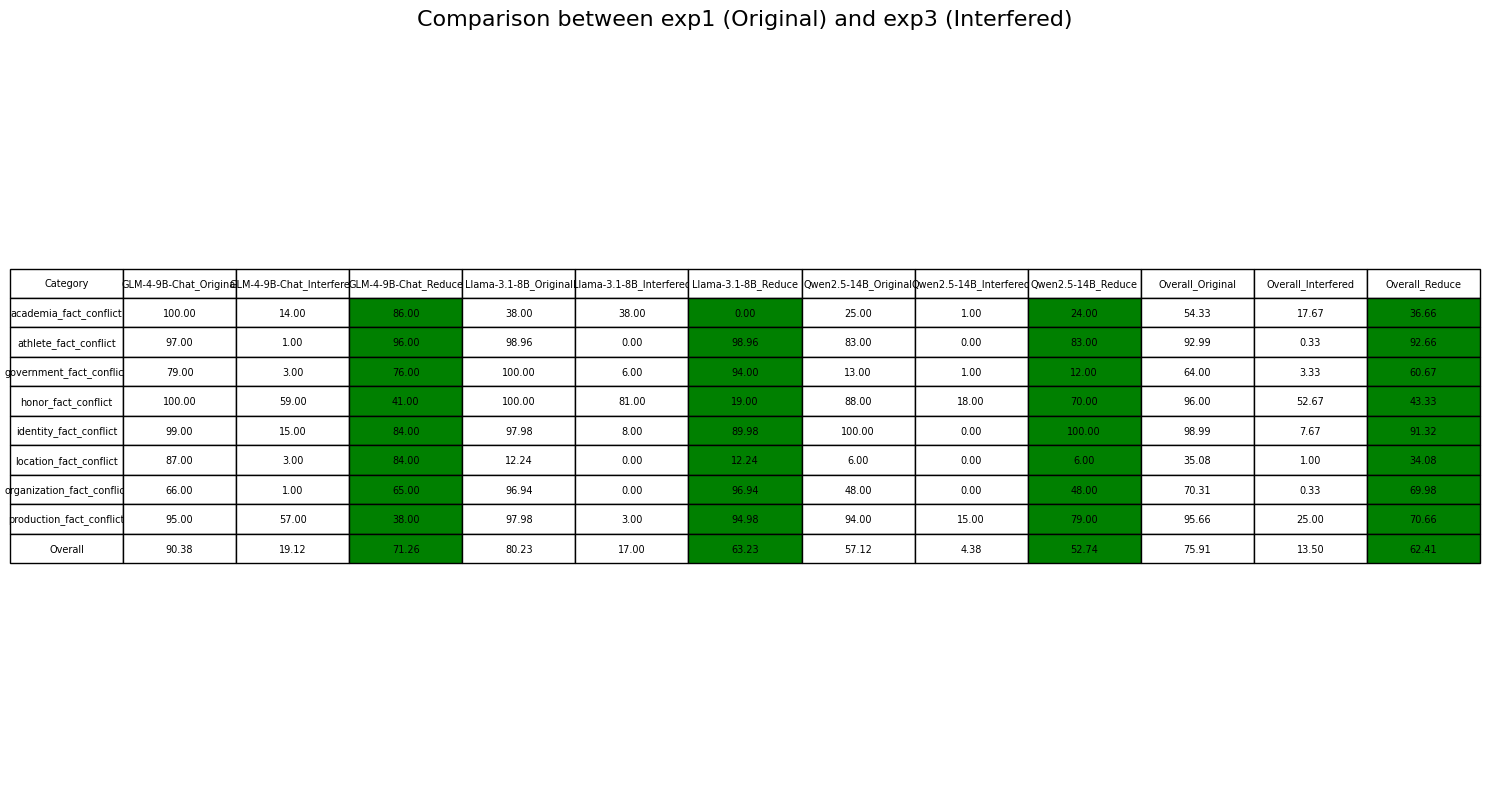

Comparison table saved to modified_results/stat/comparison_tables/comparison_table.csv
Comparison chart saved to modified_results/stat/comparison_tables/comparison_table.png


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

# 创建保存图表的目录
output_dir = "modified_results/stat/comparison_tables"
os.makedirs(output_dir, exist_ok=True)

# 读取两个CSV文件
exp1_df = pd.read_csv('modified_results/stat/exp1_final.csv', index_col=0)
exp3_df = pd.read_csv('modified_results/stat/exp3_final.csv', index_col=0)

# 创建新的DataFrame用于存储对比结果
comparison_data = {}

# 获取所有列名（LLM模型名）
models = exp1_df.columns.tolist()

# 为每个模型创建Original, Interfered, Reduce列
for model in models:
    comparison_data[f'{model}_Original'] = exp1_df[model]
    comparison_data[f'{model}_Interfered'] = exp3_df[model]
    # 计算减少量（exp1 - exp3）
    reduction = exp1_df[model] - exp3_df[model]
    comparison_data[f'{model}_Reduce'] = reduction

# 创建新的DataFrame
comparison_df = pd.DataFrame(comparison_data, index=exp1_df.index)

# 保存为CSV文件
comparison_df.to_csv(f'{output_dir}/comparison_table.csv')

# 创建可视化表格
fig, ax = plt.subplots(figsize=(15, 8))
ax.axis('tight')
ax.axis('off')

# 准备表格数据
table_data = []
for index, row in comparison_df.iterrows():
    table_row = [index]
    for model in models:
        table_row.extend([f'{row[f"{model}_Original"]:.2f}', 
                         f'{row[f"{model}_Interfered"]:.2f}', 
                         f'{row[f"{model}_Reduce"]:.2f}'])
    table_data.append(table_row)

# 创建列标签
column_labels = ['Category']
for model in models:
    column_labels.extend([f'{model}_Original', f'{model}_Interfered', f'{model}_Reduce'])

# 创建表格
table = ax.table(cellText=table_data, colLabels=column_labels, cellLoc='center', loc='center')

# 设置表格样式
table.auto_set_font_size(False)
table.set_fontsize(7)
table.scale(1, 1.5)

# 为Reduce列中正值设置红色背景
for i in range(len(table_data)):
    for j, model in enumerate(models):
        # Reduce列的索引计算
        reduce_col_index = 1 + (j * 3) + 2  # 1(类别列) + 模型索引*3 + 2(Reduce列在每个模型组中的位置)
        cell_value = table_data[i][reduce_col_index]
        try:
            value = float(cell_value)
            if value >= 0:
                table[(i + 1, reduce_col_index)].set_facecolor('green')  # 浅红色背景
        except ValueError:
            pass  # 如果不能转换为浮点数，跳过

# 设置标题
plt.title('Comparison between exp1 (Original) and exp3 (Interfered)', fontsize=16, pad=20)

# 保存图表
plt.tight_layout()
plt.savefig(f'{output_dir}/comparison_table.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

print(f"Comparison table saved to {output_dir}/comparison_table.csv")
print(f"Comparison chart saved to {output_dir}/comparison_table.png")

## exp1最终结果统计

In [9]:
import json
import os
import pandas as pd
import numpy as np

# 定义LLM模型和主题列表
llm_models = [
    "GLM-4-9B-Chat",
    "Llama-3.1-8B-Instruct", 
    "Qwen2.5-14B-Instruct"
]

topic_list = [
    "academia_fact_conflict",
    "athlete_fact_conflict", 
    "government_fact_conflict",
    "honor_fact_conflict",
    "identity_fact_conflict",
    "location_fact_conflict",
    "organization_fact_conflict",
    "production_fact_conflict"
]

# 态度标签
attitude_labels = ['Strongly Disagree', 'Disagree', 'Neither Agree nor Disagree', 'Agree', 'Strongly Agree']

def load_last_round_data(model_name, topic):
    """加载指定模型和主题的最后一轮数据"""
    file_path = f"modified_results/exp1/{model_name}/{topic}.json"
    if not os.path.exists(file_path):
        print(f"文件不存在: {file_path}")
        return []
    
    with open(file_path, 'r', encoding='utf-8') as f:
        data = json.load(f)
    
    # 筛选最后一轮（round 9）的数据
    last_round_data = [item for item in data if item.get('round') == 9]
    return last_round_data

def count_attitudes(data):
    """统计态度分布"""
    # 初始化计数器
    attitude_counts = np.zeros(5, dtype=int)  # 0-4
    
    for item in data:
        # 获取态度数值
        if 'new_opinion_digit' in item:
            att = item['new_opinion_digit']
        else:
            # 如果没有数字形式，尝试从文本转换
            op = item.get('new_opinion', '')
            if op == 'Strongly Agree': 
                att = 4
            elif op == 'Agree': 
                att = 3
            elif op == 'Neither Agree nor Disagree': 
                att = 2
            elif op == 'Disagree': 
                att = 1
            elif op == 'Strongly Disagree': 
                att = 0
            else:
                continue
        
        # 确保态度值在有效范围内
        if 0 <= att <= 4:
            attitude_counts[att] += 1
    
    return attitude_counts

def calculate_percentage(attitude_counts):
    """计算百分比"""
    total = np.sum(attitude_counts)
    if total == 0:
        return np.zeros(5)
    return (attitude_counts / total) * 100

def main():
    # 初始化结果存储
    # 9行（8个主题+overall）4列（三种LLM+overall）
    results_table = np.zeros((9, 4))  # 9行4列的表格
    
    # 主题名称（用于输出）
    topic_names = topic_list + ['Overall']
    
    # 为每个LLM模型处理数据
    for llm_idx, model_name in enumerate(llm_models):
        # print(f"处理模型: {model_name}")
        
        # 存储该模型所有主题的态度计数
        model_topic_counts = np.zeros((8, 5))  # 8个主题，5种态度
        
        # 处理每个主题
        for topic_idx, topic in enumerate(topic_list):
            # 加载最后一轮数据
            data = load_last_round_data(model_name, topic)
            
            # 统计态度分布
            attitude_counts = count_attitudes(data)
            model_topic_counts[topic_idx] = attitude_counts
            
            # 计算态度4或3的比例
            total = np.sum(attitude_counts)
            if total > 0:
                high_agreement = attitude_counts[4] + attitude_counts[3] 
                percentage = (high_agreement / total) * 100
            else:
                percentage = 0
            
            # 存储到结果表格
            results_table[topic_idx, llm_idx] = percentage
            
            # print(f"  {topic}: Strongly Agree比例 = {percentage:.2f}%")
        
        # 计算该模型的Overall（所有主题合并）
        overall_counts = np.sum(model_topic_counts, axis=0)
        total = np.sum(overall_counts)
        if total > 0:
            high_agreement_overall = overall_counts[4] + overall_counts[3]
            percentage_overall = (high_agreement_overall / total) * 100
        else:
            percentage_overall = 0
            
        results_table[8, llm_idx] = percentage_overall  # 存储Overall行
        # print(f"  Overall: Strongly Agree比例 = {percentage_overall:.2f}%")
    
    # 计算每行的平均值（三种LLM的overall）
    for row in range(9):  # 9行（8个主题+overall）
        results_table[row, 3] = np.mean(results_table[row, :3])  # 前三列的平均值
    
    # 创建DataFrame并保存为CSV
    columns = ['GLM-4-9B-Chat', 'Llama-3.1-8B', 'Qwen2.5-14B', 'Overall']
    df = pd.DataFrame(results_table, columns=columns, index=topic_names)
    
    # 保存到CSV文件
    output_file = "modified_results/stat/exp1_final.csv"
    df.to_csv(output_file, float_format='%.2f')
    print(f"\n结果已保存到: {output_file}")
    print("\n结果表格:")
    print(df)

if __name__ == "__main__":
    main()


结果已保存到: modified_results/stat/exp1_final.csv

结果表格:
                            GLM-4-9B-Chat  Llama-3.1-8B  Qwen2.5-14B  \
academia_fact_conflict            100.000     38.000000       25.000   
athlete_fact_conflict              97.000     98.958333       83.000   
government_fact_conflict           79.000    100.000000       13.000   
honor_fact_conflict               100.000    100.000000       88.000   
identity_fact_conflict             99.000     97.979798      100.000   
location_fact_conflict             87.000     12.244898        6.000   
organization_fact_conflict         66.000     96.938776       48.000   
production_fact_conflict           95.000     97.979798       94.000   
Overall                            90.375     80.228137       57.125   

                              Overall  
academia_fact_conflict      54.333333  
athlete_fact_conflict       92.986111  
government_fact_conflict    64.000000  
honor_fact_conflict         96.000000  
identity_fact_conflict    

## exp3最终结果统计

In [10]:
import json
import os
import pandas as pd
import numpy as np

# 定义LLM模型和主题列表
llm_models = [
    "GLM-4-9B-Chat",
    "Llama-3.1-8B-Instruct", 
    "Qwen2.5-14B-Instruct"
]

topic_list = [
    "academia_fact_conflict",
    "athlete_fact_conflict", 
    "government_fact_conflict",
    "honor_fact_conflict",
    "identity_fact_conflict",
    "location_fact_conflict",
    "organization_fact_conflict",
    "production_fact_conflict"
]

# 态度标签
attitude_labels = ['Strongly Disagree', 'Disagree', 'Neither Agree nor Disagree', 'Agree', 'Strongly Agree']

def load_last_round_data(model_name, topic):
    """加载指定模型和主题的最后一轮数据"""
    file_path = f"modified_results/exp3/{model_name}/{topic}.json"
    if not os.path.exists(file_path):
        print(f"文件不存在: {file_path}")
        return []
    
    with open(file_path, 'r', encoding='utf-8') as f:
        data = json.load(f)
    
    # 筛选最后一轮（round 9）的数据
    last_round_data = [item for item in data if item.get('round') == 9]
    return last_round_data

def count_attitudes(data):
    """统计态度分布"""
    # 初始化计数器
    attitude_counts = np.zeros(5, dtype=int)  # 0-4
    
    for item in data:
        # 获取态度数值
        if 'new_opinion_digit' in item:
            att = item['new_opinion_digit']
        else:
            # 如果没有数字形式，尝试从文本转换
            op = item.get('new_opinion', '')
            if op == 'Strongly Agree': 
                att = 4
            elif op == 'Agree': 
                att = 3
            elif op == 'Neither Agree nor Disagree': 
                att = 2
            elif op == 'Disagree': 
                att = 1
            elif op == 'Strongly Disagree': 
                att = 0
            else:
                continue
        
        # 确保态度值在有效范围内
        if 0 <= att <= 4:
            attitude_counts[att] += 1
    
    return attitude_counts

def calculate_percentage(attitude_counts):
    """计算百分比"""
    total = np.sum(attitude_counts)
    if total == 0:
        return np.zeros(5)
    return (attitude_counts / total) * 100

def main():
    results_table = np.zeros((9, 4))  # 9行4列的表格
    topic_names = topic_list + ['Overall']
    
    # 为每个LLM模型处理数据
    for llm_idx, model_name in enumerate(llm_models):
        model_topic_counts = np.zeros((8, 5))  # 8个主题，5种态度
        
        for topic_idx, topic in enumerate(topic_list):
            data = load_last_round_data(model_name, topic)
            
            attitude_counts = count_attitudes(data)
            model_topic_counts[topic_idx] = attitude_counts
            
            # 计算态度4或5的比例
            total = np.sum(attitude_counts)
            if total > 0:
                high_agreement = attitude_counts[4] + attitude_counts[3] 
                percentage = (high_agreement / total) * 100
            else:
                percentage = 0
            
            # 存储到结果表格
            results_table[topic_idx, llm_idx] = percentage
        
        overall_counts = np.sum(model_topic_counts, axis=0)
        total = np.sum(overall_counts)
        if total > 0:
            high_agreement_overall = overall_counts[4] + overall_counts[3]
            percentage_overall = (high_agreement_overall / total) * 100
        else:
            percentage_overall = 0
            
        results_table[8, llm_idx] = percentage_overall  
    
    for row in range(9):  
        results_table[row, 3] = np.mean(results_table[row, :3])  # 前三列的平均值
    
    columns = ['GLM-4-9B-Chat', 'Llama-3.1-8B', 'Qwen2.5-14B', 'Overall']
    df = pd.DataFrame(results_table, columns=columns, index=topic_names)
    
    # 保存到CSV文件
    output_file = "modified_results/stat/exp3_final.csv"
    df.to_csv(output_file, float_format='%.2f')
    print(f"\n结果已保存到: {output_file}")
    print("\n结果表格:")
    print(df)

if __name__ == "__main__":
    main()


结果已保存到: modified_results/stat/exp3_final.csv

结果表格:
                            GLM-4-9B-Chat  Llama-3.1-8B  Qwen2.5-14B  \
academia_fact_conflict             14.000          38.0        1.000   
athlete_fact_conflict               1.000           0.0        0.000   
government_fact_conflict            3.000           6.0        1.000   
honor_fact_conflict                59.000          81.0       18.000   
identity_fact_conflict             15.000           8.0        0.000   
location_fact_conflict              3.000           0.0        0.000   
organization_fact_conflict          1.000           0.0        0.000   
production_fact_conflict           57.000           3.0       15.000   
Overall                            19.125          17.0        4.375   

                              Overall  
academia_fact_conflict      17.666667  
athlete_fact_conflict        0.333333  
government_fact_conflict     3.333333  
honor_fact_conflict         52.666667  
identity_fact_conflict    

# 图6
同样是为了展示我们的干预策略是否有效：
我希望用干预后的数据用图2展示一下；

In [11]:
import pandas as pd
import glob
import os

# 1. 收集所有fact相关json文件路径
# llm_dirs = [
#     'results/exp3/GLM-4-9B-Chat',
#     'results/exp3/Llama-3.1-8B-Instruct',
#     'results/exp3/Qwen2.5-14B-Instruct'
#  ]

llm_dirs = [
    'modified_results/exp3/GLM-4-9B-Chat',
    'modified_results/exp3/Llama-3.1-8B-Instruct',
    'modified_results/exp3/Qwen2.5-14B-Instruct',
 ]

all_json_files = []
for d in llm_dirs:  
    all_json_files.extend(glob.glob(os.path.join(d, '*_fact_conflict.json')))
print(f"共发现 {len(all_json_files)} 个json文件")
# 2. 统计所有话题名（去掉后缀和路径，合并去重，字典序排序）
topic_names = sorted(list(set([os.path.basename(f).replace('.json','') for f in all_json_files])))

共发现 24 个json文件


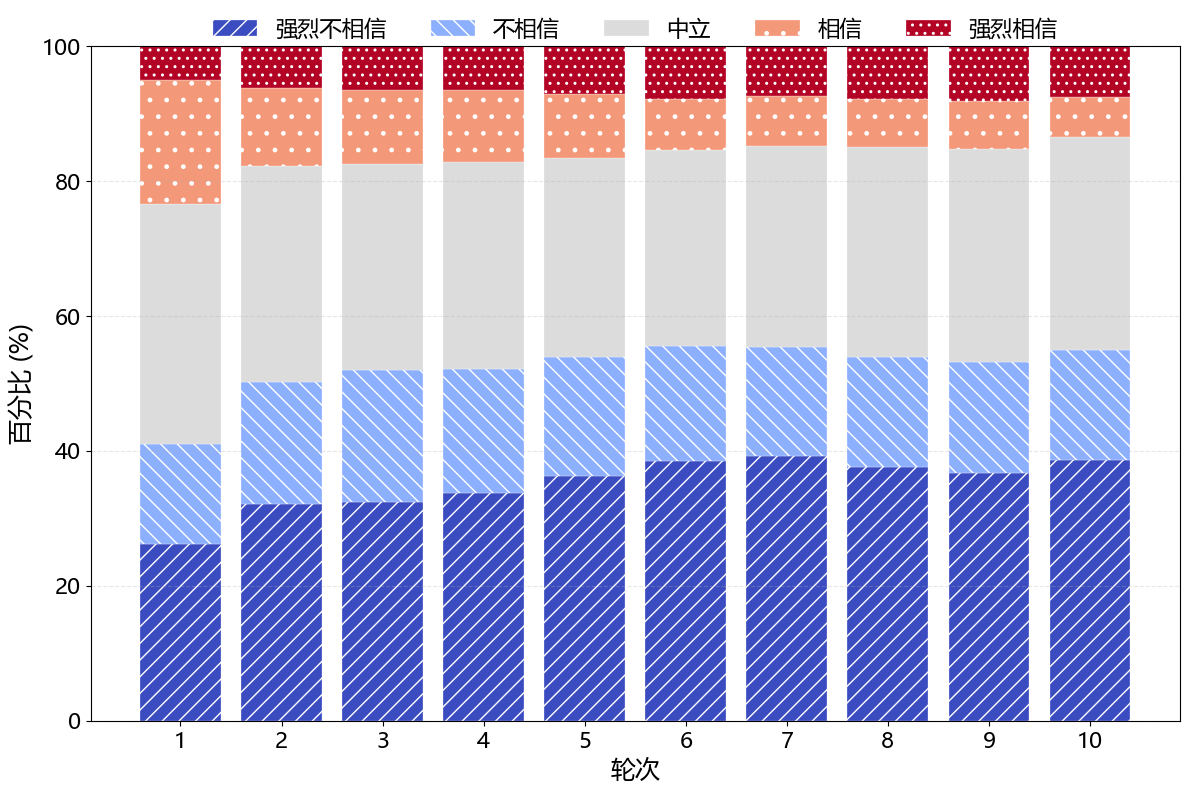

In [14]:
# 混合所有LLM和话题，统计每一轮（天）所有智能体的态度分布并绘图
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm

# 1. 统计每一轮所有智能体的态度分布
DAY_NUM = 10
attitude_counts_by_day = np.zeros((DAY_NUM, 5), dtype=int)
attitude_labels = ['强烈不相信', '不相信', '中立', '相信', '强烈相信']

for file in all_json_files:
    with open(file, 'r', encoding='utf-8') as f:
        data = json.load(f)
    for item in data:
        if ('persuasion_tweet' in item) or ('tweet' in item) or ('content' in item):
            continue
        if 'new_attitude_digit' in item:
            att = item['new_attitude_digit']
        else:
            op = item.get('new_opinion','')
            if op == 'Strongly Agree': att = 4
            elif op == 'Agree': att = 3
            elif op == 'Neither Agree nor Disagree': att = 2
            elif op == 'Disagree': att = 1
            elif op == 'Strongly Disagree': att = 0
            else: continue
        if 'day' in item:
            day = item['day']
        elif 'round' in item:
            day = item['round']
        else:
            continue
        if 0 <= day < DAY_NUM:
            attitude_counts_by_day[day, att] += 1

# 2. 计算百分比
attitude_percent_by_day = attitude_counts_by_day / attitude_counts_by_day.sum(axis=1, keepdims=True) * 100

# 3. 绘图（风格与前一图一致）
colormap = sns.color_palette("coolwarm", as_cmap=True)
colormap = [colormap(i/4) for i in range(5)]
hatch_patterns = ['//', '\\\\', '', '.', '..']
# 设置字体
# font_name = fm.FontProperties(fname=font_path).get_name()
# plt.rcParams['font.family'] = 'serif'
# plt.rcParams['font.serif'] = [font_name]
# plt.rcParams['axes.unicode_minus'] = False

TITLE_FONT_SIZE = 18
LABEL_FONT_SIZE = 16
TICK_FONT_SIZE = 16
LEGEND_FONT_SIZE = 16


fig, ax = plt.subplots(figsize=(12, 8))
bottom = np.zeros(DAY_NUM)
for i, attitude in enumerate(attitude_labels):
    ax.bar(
        np.arange(1, DAY_NUM+1), 
        attitude_percent_by_day[:, i], 
        bottom=bottom,
        color=colormap[i],
        edgecolor='white',
        linewidth=0.2,
        hatch=hatch_patterns[i],
        label=attitude,
        width=0.8
    )
    bottom += attitude_percent_by_day[:, i]

ax.set_xlabel('轮次', fontsize=TITLE_FONT_SIZE)
ax.set_ylabel('百分比 (%)', fontsize=TITLE_FONT_SIZE)
ax.set_ylim(0, 100)
ax.set_xticks(np.arange(1, DAY_NUM+1))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.07), ncol=5, frameon=False, fontsize=LEGEND_FONT_SIZE)
ax.tick_params(axis='both', which='major', labelsize=TICK_FONT_SIZE)
ax.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
# plt.savefig('picture/图6.svg', format='svg')
# plt.savefig('picture/图6.pdf', format='pdf')
plt.savefig('modified_picture/1215/图6_1215.png', format='png', dpi=600)
plt.show()

/tmp/ipykernel_65211/2694999496.py:82: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f'{int(y)}%' for y in ax.get_yticks()])


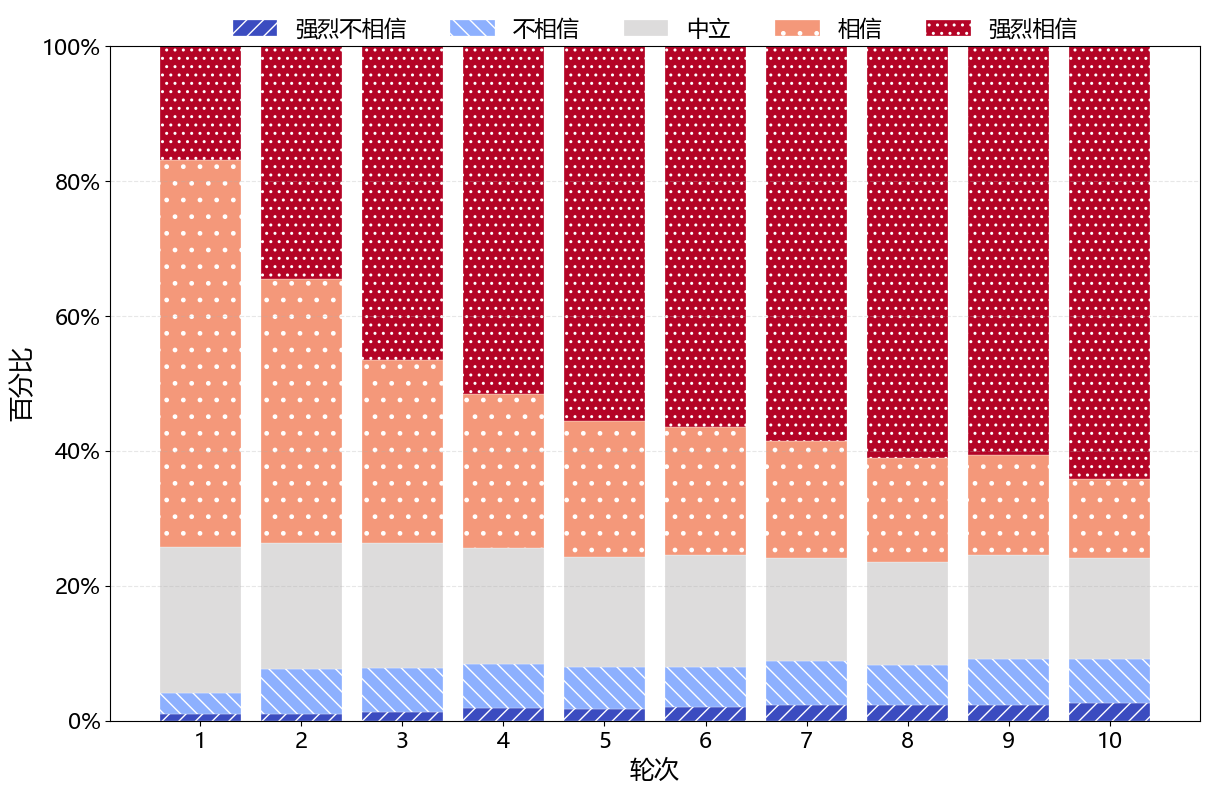

In [41]:
# 混合所有LLM和话题，统计每一轮（天）所有智能体的态度分布并绘图
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm

# 1. 统计每一轮所有智能体的态度分布
DAY_NUM = 10
attitude_counts_by_day = np.zeros((DAY_NUM, 5), dtype=int)
attitude_labels = ['强烈不相信', '不相信', '中立', '相信', '强烈相信']

for file in all_json_files:
    with open(file, 'r', encoding='utf-8') as f:
        data = json.load(f)
    for item in data:
        if ('persuasion_tweet' in item) or ('tweet' in item) or ('content' in item):
            continue
        if 'new_attitude_digit' in item:
            att = item['new_attitude_digit']
        else:
            op = item.get('new_opinion','')
            if op == 'Strongly Agree': att = 4
            elif op == 'Agree': att = 3
            elif op == 'Neither Agree nor Disagree': att = 2
            elif op == 'Disagree': att = 1
            elif op == 'Strongly Disagree': att = 0
            else: continue
        if 'day' in item:
            day = item['day']
        elif 'round' in item:
            day = item['round']
        else:
            continue
        if 0 <= day < DAY_NUM:
            attitude_counts_by_day[day, att] += 1

# 2. 计算百分比
attitude_percent_by_day = attitude_counts_by_day / attitude_counts_by_day.sum(axis=1, keepdims=True) * 100

# 3. 绘图（风格与前一图一致）
colormap = sns.color_palette("coolwarm", as_cmap=True)
colormap = [colormap(i/4) for i in range(5)]
hatch_patterns = ['//', '\\\\', '', '.', '..']
# 设置字体
# font_name = fm.FontProperties(fname=font_path).get_name()
# plt.rcParams['font.family'] = 'serif'
# plt.rcParams['font.serif'] = [font_name]
# plt.rcParams['axes.unicode_minus'] = False

TITLE_FONT_SIZE = 18
LABEL_FONT_SIZE = 16
TICK_FONT_SIZE = 16
LEGEND_FONT_SIZE = 16


fig, ax = plt.subplots(figsize=(12, 8))
bottom = np.zeros(DAY_NUM)
for i, attitude in enumerate(attitude_labels):
    ax.bar(
        np.arange(1, DAY_NUM+1), 
        attitude_percent_by_day[:, i], 
        bottom=bottom,
        color=colormap[i],
        edgecolor='white',
        linewidth=0.2,
        hatch=hatch_patterns[i],
        label=attitude,
        width=0.8
    )
    bottom += attitude_percent_by_day[:, i]

ax.set_xlabel('轮次', fontsize=TITLE_FONT_SIZE)
ax.set_ylabel('百分比', fontsize=TITLE_FONT_SIZE)
ax.set_ylim(0, 100)
ax.set_xticks(np.arange(1, DAY_NUM+1))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.07), ncol=5, frameon=False, fontsize=LEGEND_FONT_SIZE)
ax.tick_params(axis='both', which='major', labelsize=TICK_FONT_SIZE)
ax.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()

# 修改y轴的ticklabel，加上百分号
ax.set_yticklabels([f'{int(y)}%' for y in ax.get_yticks()])

# plt.savefig('picture/图6.svg', format='svg')
# plt.savefig('picture/图6.pdf', format='pdf')
plt.savefig('modified_picture/1227/图6_1227.png', bbox_inches='tight', format='png', dpi=600)
plt.show()

## 提取matlab需要的文档

In [27]:
import os
import glob
import json
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.io import savemat

def collect_json_files(llm_dirs):
    all_json_files = []
    for d in llm_dirs:
        all_json_files.extend(glob.glob(os.path.join(d, "*.json")))
    all_json_files = sorted(all_json_files)
    print(f"共发现 {len(all_json_files)} 个 json 文件")
    if len(all_json_files) == 0:
        raise RuntimeError("没有找到任何 json 文件，请检查 llm_dirs 路径是否正确。")
    return all_json_files

def map_attitude(item):
    """
    返回 att in {0,1,2,3,4} 或 None
    与你给的代码一致：
    - 优先 new_attitude_digit
    - 否则用 new_opinion 的字符串映射
    """
    if "new_attitude_digit" in item:
        att = item["new_attitude_digit"]
        if isinstance(att, (int, np.integer)) and 0 <= att <= 4:
            return int(att)
        return None

    op = item.get("new_opinion", "")
    if op == "Strongly Agree":
        return 4
    elif op == "Agree":
        return 3
    elif op == "Neither Agree nor Disagree":
        return 2
    elif op == "Disagree":
        return 1
    elif op == "Strongly Disagree":
        return 0
    return None

def map_day(item):
    """
    返回 day(round) 或 None
    """
    if "day" in item:
        return item["day"]
    if "round" in item:
        return item["round"]
    return None

def main():
    # ====== 1) 你的 LLM 输出目录（按需改） ======
    llm_dirs = [
        "modified_results/exp1/GLM-4-9B-Chat",
        "modified_results/exp1/Llama-3.1-8B-Instruct",
        "modified_results/exp1/Qwen2.5-14B-Instruct",
    ]
    all_json_files = collect_json_files(llm_dirs)

    # ====== 2) 统计每一轮所有智能体的态度分布 ======
    DAY_NUM = 10
    attitude_labels = ["强烈不相信", "不相信", "中立", "相信", "强烈相信"]
    attitude_counts_by_day = np.zeros((DAY_NUM, 5), dtype=int)

    skipped_content = 0
    skipped_bad_att = 0
    skipped_bad_day = 0

    for file in all_json_files:
        with open(file, "r", encoding="utf-8") as f:
            data = json.load(f)

        for item in data:
            # 跳过推文/内容项
            if ("persuasion_tweet" in item) or ("tweet" in item) or ("content" in item):
                skipped_content += 1
                continue

            att = map_attitude(item)
            if att is None:
                skipped_bad_att += 1
                continue

            day = map_day(item)
            if not isinstance(day, (int, np.integer)):
                skipped_bad_day += 1
                continue

            if 0 <= day < DAY_NUM:
                attitude_counts_by_day[int(day), att] += 1

    # ====== 3) 计算百分比（注意防 0 除） ======
    row_sums = attitude_counts_by_day.sum(axis=1, keepdims=True)
    attitude_percent_by_day = np.divide(
        attitude_counts_by_day,
        row_sums,
        out=np.zeros_like(attitude_counts_by_day, dtype=float),
        where=row_sums != 0,
    ) * 100

    # ====== 4) 导出颜色/纹理（保证 Matlab 与 Python 一致） ======
    cmap = sns.color_palette("coolwarm", as_cmap=True)
    colors_rgb = np.array([cmap(i / 4)[:3] for i in range(5)], dtype=float)  # 5x3
    hatch_patterns = np.array(["//", "\\\\", "", ".", ".."], dtype=object)

    # x_labels（轮次显示用）
    x_labels = np.array([str(i) for i in range(1, DAY_NUM + 1)], dtype=object)

    # ====== 5) 保存 .mat 给 Matlab 画图 ======
    out_mat = "matlab_data/plot_data_by_day_final.mat"
    savemat(
        out_mat,
        {
            "x_labels": x_labels,                                # 1..DAY_NUM
            "attitude_labels": np.array(attitude_labels, dtype=object),
            "attitude_counts_by_day": attitude_counts_by_day,    # DAY_NUM x 5
            "attitude_percent_by_day": attitude_percent_by_day,  # DAY_NUM x 5
            "colors_rgb": colors_rgb,                            # 5 x 3
            "hatch_patterns": hatch_patterns,                    # 1 x 5
            "DAY_NUM": DAY_NUM,
        },
        do_compression=True,
    )
    print(f"已保存: {out_mat}")

    # ====== 6) 额外保存 CSV 便于检查 ======
    out_csv = "matlab_data/plot_data_by_day_final.csv"
    df = pd.DataFrame(attitude_percent_by_day, columns=attitude_labels)
    df.insert(0, "round", np.arange(1, DAY_NUM + 1))
    df.to_csv(out_csv, index=False, encoding="utf-8-sig")
    print(f"已保存: {out_csv}")

    # ====== 7) 打印统计信息（可选） ======
    print("统计完成：")
    print("attitude_counts_by_day:\n", attitude_counts_by_day)
    print(f"跳过 content/tweet 项: {skipped_content}")
    print(f"跳过 无法解析态度 项: {skipped_bad_att}")
    print(f"跳过 无法解析 day/round 项: {skipped_bad_day}")

if __name__ == "__main__":
    main()

共发现 24 个 json 文件
已保存: matlab_data/plot_data_by_day_final.mat
已保存: matlab_data/plot_data_by_day_final.csv
统计完成：
attitude_counts_by_day:
 [[  24   75  519 1378  404]
 [  25  157  450  935  829]
 [  32  154  446  650 1116]
 [  45  157  410  546 1237]
 [  43  149  389  485 1331]
 [  48  144  396  454 1351]
 [  54  156  367  415 1398]
 [  54  145  365  368 1459]
 [  57  161  370  354 1446]
 [  64  156  356  280 1533]]
跳过 content/tweet 项: 240
跳过 无法解析态度 项: 63
跳过 无法解析 day/round 项: 0


# 统计csv

## 图1

In [6]:
import glob
import json
import os
import pandas as pd

# 1. 收集所有fact相关json文件路径
llm_dirs = [
    ('modified_results/exp1/GLM-4-9B-Chat-fact', 'GLM-4-9B-Chat'),
    ('modified_results/exp1/Llama-3.1-8B-Instruct-fact', 'Llama-3.1-8B-Instruct'),
    ('modified_results/exp1/Qwen2.5-14B-Instruct', 'Qwen2.5-14B-Instruct')
]

# 创建空的DataFrame来存储数据
data_list = []

# 遍历每个LLM目录
for dir_path, llm_type in llm_dirs:
    # 获取所有json文件
    json_files = glob.glob(os.path.join(dir_path, '*.json'))
    
    # 遍历每个文件
    for file in json_files:
        # 获取domain名称（文件名去掉后缀）
        domain = os.path.basename(file).replace('.json', '')
        
        # 读取JSON数据
        with open(file, 'r', encoding='utf-8') as f:
            data = json.load(f)
        
        # 只处理第0轮（初次遇到）的数据
        for item in data:
            # 跳过persuasion_tweet等非数据项
            if ('persuasion_tweet' in item) or ('tweet' in item) or ('content' in item):
                continue
            
            # 获取agent_id
            agent_id = item.get('agent_id')
            if agent_id is None:
                continue
            
            # 获取态度值
            if 'new_attitude_digit' in item:
                attitude = item['new_attitude_digit']
            else:
                op = item.get('new_opinion', '')
                if op == 'Strongly Agree': 
                    attitude = 4
                elif op == 'Agree': 
                    attitude = 3
                elif op == 'Neither Agree nor Disagree': 
                    attitude = 2
                elif op == 'Disagree': 
                    attitude = 1
                elif op == 'Strongly Disagree': 
                    attitude = 0
                else: 
                    continue
            
            # 只处理第0轮的数据
            if 'day' in item and item['day'] == 0:
                pass  # 继续处理
            elif 'round' in item and item['round'] == 0:
                pass  # 继续处理
            else:
                continue  # 不是第0轮，跳过
            
            # 获取态度原因
            attitude_reason = item.get('generated_reasons', '')
            
            # 添加到数据列表
            data_list.append({
                'agent_id': agent_id,
                'LLM_type': llm_type,
                'fact_conflict_domain': domain,
                'attitude': attitude,
                'attitude_reason': attitude_reason
            })

# 创建DataFrame
df = pd.DataFrame(data_list)

# # 保存为CSV
# df.to_csv('fig1_initial_attitude_data.csv', index=False, encoding='utf-8')

# print(f"图1数据已保存到 fig1_initial_attitude_data.csv，共 {len(df)} 条记录")
# print("列包括: agent_id, LLM_type, fact_conflict_domain, attitude, attitude_reason")

In [7]:
import pandas as pd
import os
# # 读取数据
# df = pd.read_csv('fig1_initial_attitude_data.csv')

# 获取所有不同的topic
topics = df['fact_conflict_domain'].unique()

# 创建结果DataFrame
result_data = []

# 对每个topic计算五种态度的百分比
for topic in topics:
    topic_data = df[df['fact_conflict_domain'] == topic]
    total_count = len(topic_data)
    
    # 计算每种态度的数量和百分比
    for attitude in range(5):  # 0到4
        count = len(topic_data[topic_data['attitude'] == attitude])
        percentage = (count / total_count) * 100 if total_count > 0 else 0
        result_data.append([topic, attitude, count, percentage])

# 计算overall的五种态度百分比
overall_data = []
total_count = len(df)
for attitude in range(5):  # 0到4
    count = len(df[df['attitude'] == attitude])
    percentage = (count / total_count) * 100 if total_count > 0 else 0
    overall_data.append(['overall', attitude, count, percentage])
    result_data.append(['overall', attitude, count, percentage])

# 转换为DataFrame
result_df = pd.DataFrame(result_data, columns=['topic', 'attitude', 'count', 'percentage'])

# 保存结果

os.makedirs('modified_results/stat', exist_ok=True)
result_df.to_csv('modified_results/stat/fig1_statistics.csv', index=False)

print("Fig1统计结果:")
print(result_df)

Fig1统计结果:
                         topic  attitude  count  percentage
0       academia_fact_conflict         0      0       0.000
1       academia_fact_conflict         1      0       0.000
2       academia_fact_conflict         2     19      19.000
3       academia_fact_conflict         3     81      81.000
4       academia_fact_conflict         4      0       0.000
5        athlete_fact_conflict         0      0       0.000
6        athlete_fact_conflict         1      0       0.000
7        athlete_fact_conflict         2     22      22.000
8        athlete_fact_conflict         3     75      75.000
9        athlete_fact_conflict         4      3       3.000
10      identity_fact_conflict         0      0       0.000
11      identity_fact_conflict         1      0       0.000
12      identity_fact_conflict         2     10      10.000
13      identity_fact_conflict         3     59      59.000
14      identity_fact_conflict         4     31      31.000
15    government_fact_conflict

## 图2

In [ ]:
import glob
import json
import os
import pandas as pd

# 1. 收集所有fact相关json文件路径
llm_dirs = [
    ('results/exp1/GLM-4-9B-Chat-fact', 'GLM-4-9B-Chat'),
    ('results/exp1/Llama-3.1-8B-Instruct-fact', 'Llama-3.1-8B-Instruct'),
    ('results/exp1/Qwen2.5-14B-Instruct', 'Qwen2.5-14B-Instruct')
]

# 创建空的DataFrame来存储数据
data_list = []

# 遍历每个LLM目录
for dir_path, llm_type in llm_dirs:
    # 获取所有json文件
    json_files = glob.glob(os.path.join(dir_path, '*.json'))
    
    # 遍历每个文件
    for file in json_files:
        # 获取domain名称（文件名去掉后缀）
        domain = os.path.basename(file).replace('.json', '')
        
        # 读取JSON数据
        with open(file, 'r', encoding='utf-8') as f:
            data = json.load(f)
        
        # 处理所有轮次的数据
        for item in data:
            # 跳过persuasion_tweet等非数据项
            if ('persuasion_tweet' in item) or ('tweet' in item) or ('content' in item):
                continue
            
            # 获取agent_id
            agent_id = item.get('agent_id')
            if agent_id is None:
                continue
            
            # 获取轮次
            if 'day' in item:
                round_num = item['day']
            elif 'round' in item:
                round_num = item['round']
            else:
                continue
            
            # 获取态度值
            if 'new_attitude_digit' in item:
                attitude = item['new_attitude_digit']
            else:
                op = item.get('new_opinion', '')
                if op == 'Strongly Agree': 
                    attitude = 4
                elif op == 'Agree': 
                    attitude = 3
                elif op == 'Neither Agree nor Disagree': 
                    attitude = 2
                elif op == 'Disagree': 
                    attitude = 1
                elif op == 'Strongly Disagree': 
                    attitude = 0
                else: 
                    continue
            
            # 添加到数据列表
            data_list.append({
                'agent_id': agent_id,
                'LLM_type': llm_type,
                'round': round_num,
                'fact_conflict_domain': domain,
                'attitude': attitude
            })

# 创建DataFrame
df = pd.DataFrame(data_list)

# # 保存为CSV
# df.to_csv('fig2_attitude_evolution_data.csv', index=False, encoding='utf-8')

# print(f"图2数据已保存到 fig2_attitude_evolution_data.csv，共 {len(df)} 条记录")
# print("列包括: agent_id, LLM_type, round, fact_conflict_domain, attitude")

In [ ]:
import pandas as pd

# # 读取数据
# df = pd.read_csv('fig2_attitude_evolution_data.csv')

# 获取所有不同的轮次
rounds = sorted(df['round'].unique())

# 创建结果DataFrame
result_data = []

# 对每一轮计算五种态度的百分比
for round_num in rounds:
    round_data = df[df['round'] == round_num]
    total_count = len(round_data)
    
    # 计算每种态度的数量和百分比
    for attitude in range(5):  # 0到4
        count = len(round_data[round_data['attitude'] == attitude])
        percentage = (count / total_count) * 100 if total_count > 0 else 0
        result_data.append([round_num, attitude, count, percentage])

# 转换为DataFrame
result_df = pd.DataFrame(result_data, columns=['round', 'attitude', 'count', 'percentage'])

# 保存结果
result_df.to_csv('results/stat/fig2_statistics.csv', index=False)

print("Fig2统计结果:")
print(result_df)

## 图6

In [2]:
import glob
import json
import os
import pandas as pd

# 1. 收集所有fact相关json文件路径
llm_dirs = [
    ('modified_results/exp3/GLM-4-9B-Chat', 'GLM-4-9B-Chat'),
    ('modified_results/exp3/Llama-3.1-8B-Instruct', 'Llama-3.1-8B-Instruct'),
    ('modified_results/exp3/Qwen2.5-14B-Instruct', 'Qwen2.5-14B-Instruct')
]

# 创建空的DataFrame来存储数据
data_list = []

# 遍历每个LLM目录
for dir_path, llm_type in llm_dirs:
    # 获取所有json文件
    json_files = glob.glob(os.path.join(dir_path, '*.json'))
    
    # 遍历每个文件
    for file in json_files:
        # 获取domain名称（文件名去掉后缀）
        domain = os.path.basename(file).replace('.json', '')
        
        # 读取JSON数据
        with open(file, 'r', encoding='utf-8') as f:
            data = json.load(f)
        
        # 处理所有轮次的数据
        for item in data:
            # 跳过persuasion_tweet等非数据项
            if ('persuasion_tweet' in item) or ('tweet' in item) or ('content' in item):
                continue
            
            # 获取agent_id
            agent_id = item.get('agent_id')
            if agent_id is None:
                continue
            
            # 获取轮次
            if 'day' in item:
                round_num = item['day']
            elif 'round' in item:
                round_num = item['round']
            else:
                continue
            
            # 获取态度值
            if 'new_attitude_digit' in item:
                attitude = item['new_attitude_digit']
            else:
                op = item.get('new_opinion', '')
                if op == 'Strongly Agree': 
                    attitude = 4
                elif op == 'Agree': 
                    attitude = 3
                elif op == 'Neither Agree nor Disagree': 
                    attitude = 2
                elif op == 'Disagree': 
                    attitude = 1
                elif op == 'Strongly Disagree': 
                    attitude = 0
                else: 
                    continue
            
            # 添加到数据列表
            data_list.append({
                'agent_id': agent_id,
                'LLM_type': llm_type,
                'round': round_num,
                'fact_conflict_domain': domain,
                'attitude': attitude
            })

# 创建DataFrame
df = pd.DataFrame(data_list)

# # 保存为CSV
# df.to_csv('fig2_attitude_evolution_data.csv', index=False, encoding='utf-8')

# print(f"图2数据已保存到 fig2_attitude_evolution_data.csv，共 {len(df)} 条记录")
# print("列包括: agent_id, LLM_type, round, fact_conflict_domain, attitude")

In [4]:
import pandas as pd

# # 读取数据
# df = pd.read_csv('fig2_attitude_evolution_data.csv')

# 获取所有不同的轮次
rounds = sorted(df['round'].unique())

# 创建结果DataFrame
result_data = []

# 对每一轮计算五种态度的百分比
for round_num in rounds:
    round_data = df[df['round'] == round_num]
    total_count = len(round_data)
    
    # 计算每种态度的数量和百分比
    for attitude in range(5):  # 0到4
        count = len(round_data[round_data['attitude'] == attitude])
        percentage = (count / total_count) * 100 if total_count > 0 else 0
        result_data.append([round_num, attitude, count, percentage])

# 转换为DataFrame
result_df = pd.DataFrame(result_data, columns=['round', 'attitude', 'count', 'percentage'])

# 保存结果
result_df.to_csv('modified_results/stat/fig6_statistics.csv', index=False)

print("Fig6统计结果:")
print(result_df)

Fig6统计结果:
    round  attitude  count  percentage
0       0         0    629   26.208333
1       0         1    357   14.875000
2       0         2    853   35.541667
3       0         3    441   18.375000
4       0         4    120    5.000000
5       1         0    771   32.125000
6       1         1    434   18.083333
7       1         2    768   32.000000
8       1         3    279   11.625000
9       1         4    148    6.166667
10      2         0    779   32.458333
11      2         1    468   19.500000
12      2         2    735   30.625000
13      2         3    262   10.916667
14      2         4    156    6.500000
15      3         0    811   33.791667
16      3         1    439   18.291667
17      3         2    739   30.791667
18      3         3    253   10.541667
19      3         4    158    6.583333
20      4         0    872   36.333333
21      4         1    421   17.541667
22      4         2    709   29.541667
23      4         3    228    9.500000
24      4      

In [5]:
# 读取fig6统计数据
root_dir = "modified_results/stat"
fig6_df = pd.read_csv(f'{root_dir}/fig6_statistics.csv')

# 创建透视表格式的fig6统计结果
fig6_pivot = fig6_df.pivot(index='round', columns='attitude', values='percentage')
fig6_pivot.columns = ['态度0(%)', '态度1(%)', '态度2(%)', '态度3(%)', '态度4(%)']
fig6_pivot.reset_index(inplace=True)

# 对数据内容保留两位小数
fig6_pivot = fig6_pivot.round(2)

# 保存fig6的透视表格式结果
fig6_pivot.to_csv(f'{root_dir}/fig6_summary.csv', index=False, encoding='utf-8-sig')

## Summary

In [ ]:
import pandas as pd

root_dir = "results/stat"
# 读取fig1统计数据
fig1_df = pd.read_csv(f'{root_dir}/fig1_statistics.csv')

# 创建透视表格式的fig1统计结果
fig1_pivot = fig1_df.pivot(index='topic', columns='attitude', values='percentage')
fig1_pivot.columns = ['态度0(%)', '态度1(%)', '态度2(%)', '态度3(%)', '态度4(%)']
fig1_pivot.reset_index(inplace=True)

# 对数据内容保留两位小数
fig1_pivot = fig1_pivot.round(2)

# 保存fig1的透视表格式结果
fig1_pivot.to_csv(f'{root_dir}/fig1_summary.csv', index=False, encoding='utf-8-sig')

# 读取fig2统计数据
fig2_df = pd.read_csv(f'{root_dir}/fig2_statistics.csv')

# 创建透视表格式的fig2统计结果
fig2_pivot = fig2_df.pivot(index='round', columns='attitude', values='percentage')
fig2_pivot.columns = ['态度0(%)', '态度1(%)', '态度2(%)', '态度3(%)', '态度4(%)']
fig2_pivot.reset_index(inplace=True)

# 对数据内容保留两位小数
fig2_pivot = fig2_pivot.round(2)

# 保存fig2的透视表格式结果
fig2_pivot.to_csv(f'{root_dir}/fig2_summary.csv', index=False, encoding='utf-8-sig')

# 读取fig6统计数据
fig6_df = pd.read_csv(f'{root_dir}/fig6_statistics.csv')

# 创建透视表格式的fig6统计结果
fig6_pivot = fig6_df.pivot(index='round', columns='attitude', values='percentage')
fig6_pivot.columns = ['态度0(%)', '态度1(%)', '态度2(%)', '态度3(%)', '态度4(%)']
fig6_pivot.reset_index(inplace=True)

# 对数据内容保留两位小数
fig6_pivot = fig6_pivot.round(2)

# 保存fig6的透视表格式结果
fig6_pivot.to_csv(f'{root_dir}/fig6_summary.csv', index=False, encoding='utf-8-sig')

print("Fig1统计汇总 (按topic分类):")
print(fig1_pivot)
print("\nFig2统计汇总 (按轮次分类):")
print(fig2_pivot)
print("\nFig6统计汇总 (按topic分类):")
print(fig6_pivot)


# 测试Baseline

### 测试将警告加在观点更新的 baseline

In [18]:
MODELS = ["Qwen2.5-14B-Instruct", "GLM-4-9B-Chat", "Llama-3.1-8B-Instruct"]
TOPICS = ['academia', 'athlete', 'identity', 'government', 'location', 'organization', 'production', 'honor']
LABELS = ["学术", "体育", "人物", "历史", "宗教", "地理", "音乐", "媒体"]
note_exp_root_dir = "./modified_results/exp1"
note_exp_model_dir = [f"{note_exp_root_dir}/{model_name}_100_10_notes" for model_name in MODELS]
note_exp_filepath_split_by_topic = {}
for topic, label in zip(TOPICS, LABELS):
    note_exp_filepath_split_by_topic[label] = []
    for model_dir in note_exp_model_dir:
        filepath = f"{model_dir}/{topic}_fact_conflict.json"
        with open(filepath, 'r', encoding='utf-8') as f:
            data = json.load(f)
            note_exp_filepath_split_by_topic[label].append(data)

In [19]:
opinon_per_topic = {label: [] for label in LABELS}
for label in LABELS:
    for records in note_exp_filepath_split_by_topic[label]:
        for record in records:
            if 'agent_id' in record and record['round'] == 9:
                opinon_per_topic[label].append(record['new_opinion_digit'])

In [20]:
agents_agree_counts = {}
for label in LABELS:
    agents_agree_counts[label] = (Counter(opinon_per_topic[label])[3] + Counter(opinon_per_topic[label])[4])/len(opinon_per_topic[label]) * 100
Ordered_Labels = ['历史', '媒体', '音乐', '学术', '人物', '体育', '地理', '宗教']
agents_agree_counts

{'学术': 46.33333333333333,
 '体育': 67.33333333333333,
 '人物': 75.33333333333333,
 '历史': 39.666666666666664,
 '宗教': 14.333333333333334,
 '地理': 19.333333333333332,
 '音乐': 82.0,
 '媒体': 64.33333333333333}

In [21]:
for label in Ordered_Labels:
    print(f"{label}: {agents_agree_counts[label]:.2f}%")
print(f"平均值: {np.mean(list(agents_agree_counts.values())):.2f}%")

历史: 39.67%
媒体: 64.33%
音乐: 82.00%
学术: 46.33%
人物: 75.33%
体育: 67.33%
地理: 19.33%
宗教: 14.33%
平均值: 51.08%


### 测试 SheepDog

In [23]:
MODELS = ["Qwen2.5-14B-Instruct", "GLM-4-9B-Chat", "Llama-3.1-8B-Instruct"]
TOPICS = ['academia', 'athlete', 'identity', 'government', 'location', 'organization', 'production', 'honor']
LABELS = ["学术", "体育", "人物", "历史", "宗教", "地理", "音乐", "媒体"]
note_exp_root_dir = "./modified_results/exp3"
note_exp_model_dir = [f"{note_exp_root_dir}/{model_name}_100_10_SheepDog" for model_name in MODELS]
note_exp_filepath_split_by_topic = {}
for topic, label in zip(TOPICS, LABELS):
    note_exp_filepath_split_by_topic[label] = []
    for model_dir in note_exp_model_dir:
        filepath = f"{model_dir}/{topic}_fact_conflict.json"
        with open(filepath, 'r', encoding='utf-8') as f:
            data = json.load(f)
            note_exp_filepath_split_by_topic[label].append(data)

In [24]:
opinon_per_topic = {label: [] for label in LABELS}
for label in LABELS:
    for records in note_exp_filepath_split_by_topic[label]:
        for record in records:
            if 'agent_id' in record and record['round'] == 9:
                opinon_per_topic[label].append(record['new_opinion_digit'])

In [25]:
agents_agree_counts = {}
for label in LABELS:
    agents_agree_counts[label] = (Counter(opinon_per_topic[label])[3] + Counter(opinon_per_topic[label])[4])/len(opinon_per_topic[label]) * 100
Ordered_Labels = ['历史', '媒体', '音乐', '学术', '人物', '体育', '地理', '宗教']
agents_agree_counts

{'学术': 16.0,
 '体育': 0.0,
 '人物': 11.666666666666666,
 '历史': 34.66666666666667,
 '宗教': 0.33333333333333337,
 '地理': 1.0,
 '音乐': 39.666666666666664,
 '媒体': 66.66666666666666}

In [26]:
for label in Ordered_Labels:
    print(f"{label}: {agents_agree_counts[label]:.2f}%")
print(f"平均值: {np.mean(list(agents_agree_counts.values())):.2f}%")

历史: 34.67%
媒体: 66.67%
音乐: 39.67%
学术: 16.00%
人物: 11.67%
体育: 0.00%
地理: 1.00%
宗教: 0.33%
平均值: 21.25%
